# BUSN 35137 — Final Project (Group 2): Forecasting the stock-bond correlation

**Question.** Which group of predictors best forecasts next quarter's US stock-bond correlation out of sample: **A** macro fundamentals, **B** liquidity and stress, or **C** news? Does each group add anything beyond the correlation's own history and beyond the other groups?

**Target.** `target_next3m_corr` for month $t$ is the correlation of daily US stock returns (Ken French Mkt-RF + RF) and daily CRSP 10-year fixed-term Treasury returns over months $t+1$ to $t+3$. All predictors in row $t$ are known at the end of month $t$ (already lagged in `panel_monthly.csv`).

**Design**

| Window | Rows (forecast month) | Role |
|---|---|---|
| Burn-in | 1987-01 to 1999-12 (156) | Starting history only. Never scored. Its data stays in every expanding fit. |
| Validation | 2000-01 to 2017-12 (216; 214 scored) | Real-time OOS forecasts. Used for the team's design choices: best method per predictor set. |
| Test | 2018-01 to 2025-09 (93) | Real-time OOS forecasts with every choice frozen. Run **once** (`RUN_TEST`). |

* **Yearly expanding refits, identical in validation and test.** For forecast year $Y$, models are fit on rows 1987-01 to $(Y-1)$-10 and forecast rows $Y$-01 to $Y$-12. Row $t$'s target ends in month $t+3$, so at the end of January $Y$ (when the first year-$Y$ forecast is made) the newest realized target is row $(Y-1)$-10. Dropping rows $(Y-1)$-11 and -12 is the 2-row overlap rule.
* **Hyperparameters are re-tuned at every refit** by purged, blocked 5-fold CV on the data available at that point: 5 consecutive blocks, no shuffling, 2 rows dropped on each side of every held-out block.
* **The last 2 validation rows (2017-11, 2017-12) are forecast but not scored.** Their targets run into 2018 and overlap test-window targets, so scoring them would let test-period returns influence design choices.
* **Every model contains the trailing correlation.** In the linear-family models it enters unpenalized: its fit is partialled out first (Frisch–Waugh), and penalties act only on what a group adds.
* **Benchmarks:** expanding historical mean, trailing correlation (random walk), and the own-history regression (target on trailing correlation). The own-history model is the bar.
* **Reporting.** Tables lead with the **stand-alone** out-of-sample $R^2$ (vs. the expanding historical mean), with the own-history and random-walk benchmarks shown alongside, so the size of each gain is visible: persistence alone explains about 71% of the variance and the predictor groups add a few points on top. The decision rule below is unchanged and still uses $R^2$ vs. own history and Clark–West.

**Pre-registered decision rule (fixed before the test run).**
1. Primary metric: test $R^2$ vs. the own-history model. A group *adds value* only if the one-sided Clark–West test rejects at 5% (Newey–West, 2 lags).
2. Winner: the top-ranked group that adds value. It is a *clear* winner only if Diebold–Mariano also rejects (5%) against the runner-up; otherwise the groups are reported as not distinguishable.
3. Sign accuracy and the combination weights are secondary evidence, never tie-breakers.
4. Method check: the pre-specified headline model (equal-weight ridge + PCR) is run on every group. If the ranking holds there too, the result reflects information rather than method.
5. Second bar (reported, not part of the rule): $R^2$ and Clark–West vs. the **random walk** (forecast = trailing correlation). In validation the random walk beats the own-history regression, whose intercept is pulled toward the positive 1990s mean, so a group that beats both bars is the more convincing result. This was added before the test run.

Runtime: a few minutes on a multi-core machine (refits run in parallel over years). Tables and figures are written to `output/`.

In [1]:
import io, json, time, warnings, zipfile
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import enet_path

warnings.filterwarnings("ignore", category=ConvergenceWarning)

DATA = Path("Zip File All Data")
if not DATA.exists():
    DATA = Path("Final Project") / "Zip File All Data"
OUT = DATA.parent / "output"
OUT.mkdir(exist_ok=True)

SEED = 0
FIRST, BURNIN_END, VAL_END, TEST_END = (pd.Period(m, "M") for m in ["1987-01", "1999-12", "2017-12", "2025-09"])
VAL_YEARS = list(range(2000, 2018))
TEST_YEARS = list(range(2018, 2026))
EMBARGO = 2          # target of row t covers months t+1..t+3, so the 2 latest rows of any fit sample are unrealized
N_FOLDS = 5          # purged, blocked CV at every refit
NW_LAGS = 2          # Newey-West lags: 3-month overlapping targets -> MA(2) forecast errors
COMB_WINDOW, COMB_MIN = 36, 12   # combination: trailing 36 realized errors, equal weights until 12 exist
ROLL_YEARS = 15      # robustness: rolling instead of expanding window
N_JOBS = -1
RUN_TEST = True      # flip to True ONCE, after the design is frozen

RIDGE_REL_GRID = np.logspace(-6, 2, 49)        # ridge penalty = rel * s_max^2 of the fit-sample design
ENET_REL_GRID = np.logspace(0, -3, 40)         # lasso / EN penalty = rel * alpha_max of the fit sample
ENET_L1_GRID = [0.2, 0.5, 0.8]
RF_GRID = [dict(max_depth=d, min_samples_leaf=l, max_features=f)
           for d in [2, 3, 5, None] for l in [5, 10, 20] for f in [0.33, 0.66, 1.0]]
RF_TREES = 300
GB_GRID = [dict(max_depth=d, learning_rate=lr) for d in [1, 2, 3] for lr in [0.01, 0.1]]
GB_MAX_TREES = 500


@contextmanager
def timer(label):
    t0 = time.perf_counter()
    yield
    print(f"[{label}: {time.perf_counter() - t0:.1f}s]")


import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from cycler import cycler
from IPython.display import display

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- chart style (same as the HW2 notebook) ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "lines.linewidth": 1.6, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 8.5, "text.color": INK,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "figure.dpi": 110,
})


def zero_line(ax, vertical=False):
    (ax.axvline if vertical else ax.axhline)(0, color=MUTED, linewidth=0.9, zorder=1)


def save_table(df, name, floatfmt="{:.2f}"):
    """Write a table as CSV and as a markdown file for the paper."""
    df.to_csv(OUT / f"{name}.csv")
    cols = [str(df.index.name or "")] + [str(c) for c in df.columns]
    fmt = lambda v: floatfmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v) else ("" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join([str(i)] + [fmt(v) for v in row]) + " |" for i, row in zip(df.index, df.to_numpy())]
    (OUT / f"{name}.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Data

`panel_monthly.csv` has one row per month with the target, the trailing-correlation benchmark and every predictor, already lagged to when it would have been known. The cell restricts it to the forecast window (1987-01 to 2025-09, when all three groups have data), labels the windows and checks the row counts and missing values.

In [2]:
GROUPS = {
    "A": ["infl_yoy", "infl_vol12", "exp_infl_mich", "unemp_chg12", "tbill", "term_spread"],
    "B": ["credit_spread", "cp_spread", "vix_monthend", "treasury_noise", "ps_liquidity"],
    "C": ["epu_overall", "epu_monetary", "emv_inflation_share", "emv_rates_share", "emv_monetary_share",
          "emv_macro_news_share"],
    "D": ["wsj_Federal Reserve", "wsj_Recession", "wsj_Oil market", "wsj_Treasury bonds", "wsj_Financial crisis",
          "wsj_Government budgets"],
}
GROUP_NAMES = {"A": "Macro", "B": "Liquidity", "C": "News", "D": "WSJ topics"}
# predictor sets for the main analysis: each group alone, every pair, all three
SETS = {"A": ["A"], "B": ["B"], "C": ["C"], "A+B": ["A", "B"], "A+C": ["A", "C"], "B+C": ["B", "C"],
        "A+B+C": ["A", "B", "C"]}
set_cols = lambda s: [c for g in SETS[s] for c in GROUPS[g]]

panel = pd.read_csv(DATA / "panel_monthly.csv")
panel["month"] = pd.PeriodIndex(panel["month"], freq="M")
panel = panel.set_index("month")
df = panel.loc[FIRST:TEST_END].rename(columns={"target_next3m_corr": "y", "bench_trailing3m_corr": "h"})
df["window"] = np.select([df.index <= BURNIN_END, df.index <= VAL_END], ["burn-in", "validation"], "test")

VAL_SCORE_END = VAL_END - EMBARGO          # 2017-10: last validation row whose target ends before test targets start
val_idx = df.loc[pd.Period("2000-01", "M"):VAL_SCORE_END].index
test_idx = df.loc[pd.Period("2018-01", "M"):TEST_END].index
assert (df["window"].value_counts()[["burn-in", "validation", "test"]] == [156, 216, 93]).all()
assert len(val_idx) == 214 and val_idx[-1] + 3 < test_idx[0] + 1     # scored validation targets end before test targets begin
abc = [c for g in "ABC" for c in GROUPS[g]]
assert df[["y", "h"] + abc].notna().all().all(), "A/B/C, target and benchmark must be complete in the window"
print(f"Forecast window {df.index[0]} to {df.index[-1]}: {len(df)} rows; "
      f"WSJ topics available through {df[GROUPS['D']].dropna().index[-1]}")

summary = df.groupby("window", sort=False)["y"].agg(["count", "mean", "std", "min", "max"])
summary["share > 0 (%)"] = df.groupby("window", sort=False)["y"].apply(lambda s: 100 * (s > 0).mean())
summary.index.name = "window"
display(summary.round(3))
display(df.groupby("window", sort=False)[abc].mean().T.round(3))

Forecast window 1987-01 to 2025-09: 465 rows; WSJ topics available through 2017-06


,count,mean,std,min,max,share > 0 (%)
window,,,,,,
burn-in,156,0.346,0.281,-0.601,0.748,86.538
validation,216,-0.342,0.270,-0.793,0.257,13.889
test,93,-0.136,0.323,-0.653,0.489,32.258


window,burn-in,validation,test
infl_yoy,3.209,2.149,3.430
infl_vol12,0.176,0.356,0.304
exp_infl_mich,3.140,2.973,3.554
unemp_chg12,-0.214,0.009,-0.030
tbill,5.313,1.589,2.529
term_spread,1.792,1.944,0.281
credit_spread,0.841,1.057,0.894
cp_spread,0.569,0.300,0.152
vix_monthend,19.771,19.871,19.950
treasury_noise,3.727,2.905,1.941


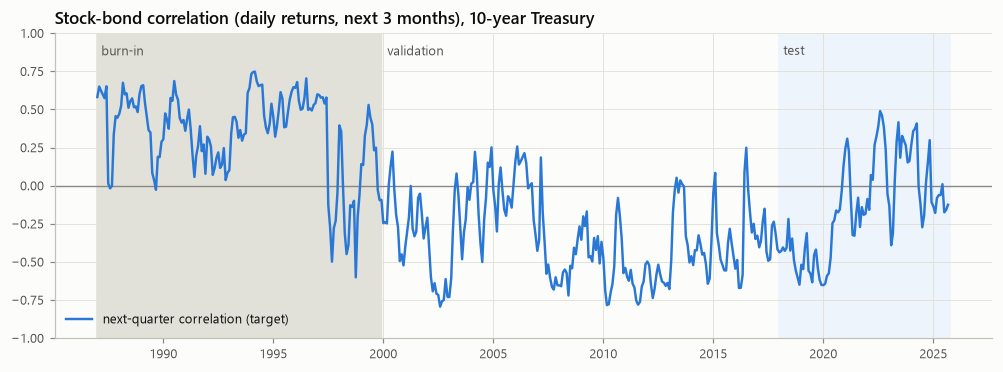

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.6))
t = df.index.to_timestamp()
for lo, hi, lab in [("1987-01", "1999-12", "burn-in"), ("2000-01", "2017-12", "validation"), ("2018-01", "2025-09", "test")]:
    ax.axvspan(pd.Period(lo, "M").to_timestamp(), pd.Period(hi, "M").to_timestamp(how="end"),
               color={"burn-in": GRID, "validation": SURFACE, "test": "#eef4fc"}[lab], zorder=0)
    ax.text(pd.Period(lo, "M").to_timestamp(), 0.92, " " + lab, color=INK2, fontsize=8.5, va="top")
ax.plot(t, df["y"], color=PALETTE[0], label="next-quarter correlation (target)")
zero_line(ax)
ax.set_ylim(-1, 1)
ax.set_title("Stock-bond correlation (daily returns, next 3 months), 10-year Treasury")
ax.legend(loc="lower left")
save_fig(fig, "fig_correlation_history")
plt.show()

## 2. Rebuilding the target from daily data

The 5- and 30-year robustness checks need the target and trailing correlation for other maturities, so the target is rebuilt from the raw daily files: Ken French daily Mkt-RF + RF and CRSP fixed-term Treasury index returns (`TDRETADJ`, in %). The rebuilt 10-year series must reproduce the panel's columns exactly before the 5- and 30-year series are used.

In [4]:
with zipfile.ZipFile(DATA / "T1_Stock_Returns_Daily_KenFrench.zip") as z:
    lines = z.read(z.namelist()[0]).decode("latin-1").splitlines()
rows = [l for l in lines if len(l.split(",")[0].strip()) == 8 and l.split(",")[0].strip().isdigit()]
ff = pd.read_csv(io.StringIO("\n".join(rows)), header=None, names=["d", "mkt_rf", "smb", "hml", "rf"])
stock = pd.Series((ff["mkt_rf"] + ff["rf"]).to_numpy(), index=pd.to_datetime(ff["d"].astype(str)), name="stock")

with zipfile.ZipFile(DATA / "T2_Treasury_Returns_Daily_CRSP_FixedTerm.zip") as z:
    name = next(n for n in z.namelist() if n.endswith(".csv") and n.upper() != "EMVMACRONEWS.CSV")
    tr = pd.read_csv(z.open(name), usecols=["KYTREASNOX", "CALDT", "TDRETADJ"]).dropna(subset=["TDRETADJ"])
tr["CALDT"] = pd.to_datetime(tr["CALDT"])
bonds = tr.pivot(index="CALDT", columns="KYTREASNOX", values="TDRETADJ")
MATURITY_CODE = {"5Y": 2000005, "10Y": 2000007, "30Y": 2000009}


def corr_series(bond):
    """Return (target, trailing) monthly series: corr over months t+1..t+3 and over t-2..t."""
    d = pd.concat([stock, bond], axis=1, join="inner").dropna()
    d.columns = ["s", "b"]
    m = d.index.to_period("M")
    months = pd.period_range(panel.index[0], panel.index[-1], freq="M")
    # monthly sums for a rolling 3-month Pearson correlation
    g = pd.DataFrame({"n": 1, "s": d["s"], "b": d["b"], "ss": d["s"] ** 2, "bb": d["b"] ** 2,
                      "sb": d["s"] * d["b"]}).groupby(m).sum().reindex(months, fill_value=0)
    r = g.rolling(3).sum()
    cov = r["sb"] - r["s"] * r["b"] / r["n"]
    corr3 = cov / np.sqrt((r["ss"] - r["s"] ** 2 / r["n"]) * (r["bb"] - r["b"] ** 2 / r["n"]))
    corr3[r["n"] < 20] = np.nan                    # corr3 at month m covers m-2..m
    return corr3.shift(-3), corr3                  # target(t) = corr over t+1..t+3 = corr3 at t+3


targets = {k: corr_series(bonds[c]) for k, c in MATURITY_CODE.items()}
for col, s in [("target_next3m_corr", targets["10Y"][0]), ("bench_trailing3m_corr", targets["10Y"][1])]:
    diff = (s - panel[col]).dropna().abs()
    print(f"10Y rebuilt vs panel {col}: {len(diff)} months compared, max abs difference {diff.max():.2e}")
    assert diff.max() < 1e-10 and s.loc[FIRST:TEST_END].notna().all()
print(pd.DataFrame({k: v[0].loc[FIRST:TEST_END].describe() for k, v in targets.items()}).T.round(3))

10Y rebuilt vs panel target_next3m_corr: 489 months compared, max abs difference 3.44e-15
10Y rebuilt vs panel bench_trailing3m_corr: 490 months compared, max abs difference 3.44e-15
     count   mean    std    min    25%    50%    75%    max
5Y   465.0 -0.078  0.400 -0.795 -0.413 -0.123  0.271  0.739
10Y  465.0 -0.070  0.417 -0.793 -0.427 -0.100  0.299  0.748
30Y  465.0 -0.055  0.414 -0.812 -0.396 -0.086  0.300  0.739


## 3. Methods and the recursive forecasting loop

Every method maps a fitting sample to forecasts for **every point of its hyperparameter grid at once**. The same function serves the CV folds and the final refit, so tuning and forecasting cannot differ in how a model is built.

| Method | Specification | Grid (re-tuned by purged blocked 5-fold CV at each refit) |
|---|---|---|
| Own history (benchmark) | OLS of the target on the trailing correlation | — |
| Historical mean (benchmark) | mean of the fit-sample target | — |
| Trailing correlation (benchmark) | forecast = trailing correlation | — |
| OLS | OLS on trailing correlation + group predictors | — |
| Ridge | Frisch–Waugh residuals, standardized; closed-form SVD path (as in HW2) | 49 penalties, $\alpha = \text{rel}\times s_{\max}^2$, rel $\in [10^{-6}, 10^{2}]$ |
| Lasso / Elastic net | same residuals; `enet_path` | 40 penalties, $\alpha = \text{rel}\times\alpha_{\max}$, rel $\in [10^{-3}, 1]$; EN `l1_ratio` $\in \{0.2, 0.5, 0.8\}$ |
| PCR | same residuals; first $k$ principal components | $k \in \{0, \dots, p\}$ ($k = 0$ is own history) |
| PLS | same residuals; `PLSRegression(scale=False)` | $k \in \{0, \dots, p\}$ |
| Random forest | trailing correlation + group predictors | depth $\in\{2,3,5,\text{None}\}$ × min leaf $\in\{5,10,20\}$ × max features $\in\{0.33,0.66,1\}$; 300 trees |
| Gradient boosting | trailing correlation + group predictors, `subsample = 0.8` | depth $\in\{1,2,3\}$ × learning rate $\in\{0.01,0.1\}$; trees $\le 500$ via `staged_predict` |
| **Headline** (pre-specified) | equal-weight average of the ridge and PCR forecasts | inherits both |

Relative penalties (rel × $s_{\max}^2$, rel × $\alpha_{\max}$) keep a "penalty level" comparable as the fitting sample grows. Ridge at its largest penalty, lasso at rel = 1 and PCR/PLS at $k = 0$ all reproduce the own-history model, so every penalized method can choose to add nothing.

In [5]:
# Every method maps a fit sample (X, h, y) and an evaluation sample (X_e, h_e) to forecasts for EVERY point of its
# hyperparameter grid at once: an array of shape (n_eval, n_grid). Tuning and refitting both go through this one
# function, so CV and the final fit can never differ in how the model is built.
#   X: group predictors, h: trailing correlation (own history), y: next-quarter correlation.

def _design(h):
    return np.column_stack([np.ones(len(h)), h])

def partial_out(X, h, y, X_e, h_e):
    """Frisch-Waugh: remove the own-history fit from y and X, standardize the residual predictors.
    Returns residualized/standardized fit and eval predictors, the residual target, and the own-history
    forecast for the eval rows. Penalties then act only on what the group adds beyond own history."""
    H, H_e = _design(h), _design(h_e)
    b, *_ = np.linalg.lstsq(H, y, rcond=None)
    G, *_ = np.linalg.lstsq(H, X, rcond=None)
    Xr, Xr_e = X - H @ G, X_e - H_e @ G
    sd = Xr.std(axis=0)
    sd[sd == 0] = 1.0
    return Xr / sd, Xr_e / sd, y - H @ b, H_e @ b


class OwnHistory:
    name, grid = "Own history", [None]
    def predict_grid(self, X, h, y, X_e, h_e):
        b, *_ = np.linalg.lstsq(_design(h), y, rcond=None)
        return (_design(h_e) @ b)[:, None]
    def describe(self, k): return "—"


class HistMean:
    name, grid = "Historical mean", [None]
    def predict_grid(self, X, h, y, X_e, h_e):
        return np.full((len(h_e), 1), y.mean())
    def describe(self, k): return "—"


class OLS:
    name, grid = "OLS", [None]
    def predict_grid(self, X, h, y, X_e, h_e):
        Z = np.column_stack([_design(h), X])
        b, *_ = np.linalg.lstsq(Z, y, rcond=None)
        return (np.column_stack([_design(h_e), X_e]) @ b)[:, None]
    def describe(self, k): return "—"


class Ridge:
    name, grid = "Ridge", list(RIDGE_REL_GRID)
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        U, s, Vt = np.linalg.svd(Z, full_matrices=False)
        alphas = RIDGE_REL_GRID * s[0] ** 2
        shrink = s[:, None] / (s[:, None] ** 2 + alphas[None, :])          # (p, n_grid)
        coefs = Vt.T @ (shrink * (U.T @ r)[:, None])                      # (p, n_grid)
        return base[:, None] + Z_e @ coefs
    def describe(self, k): return f"rel = {RIDGE_REL_GRID[k]:.2g}"


class ENet:
    def __init__(self, l1_grid, name):
        self.l1_grid, self.name = l1_grid, name
        self.grid = [(l1, rel) for l1 in l1_grid for rel in ENET_REL_GRID]
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        out = []
        for l1 in self.l1_grid:
            amax = np.abs(Z.T @ r).max() / (len(r) * l1)
            _, coefs, _ = enet_path(Z, r, l1_ratio=l1, alphas=amax * ENET_REL_GRID, max_iter=5000)
            out.append(base[:, None] + Z_e @ coefs)
        return np.hstack(out)
    def describe(self, k):
        l1, rel = self.grid[k]
        return f"rel = {rel:.2g}" if len(self.l1_grid) == 1 else f"l1 = {l1}, rel = {rel:.2g}"


class PCR:
    name = "PCR"
    def __init__(self, p): self.grid = list(range(0, p + 1))          # k = 0 is own history
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        _, _, Vt = np.linalg.svd(Z, full_matrices=False)
        F, F_e = Z @ Vt.T, Z_e @ Vt.T                       # PC scores (columns ordered by variance)
        g = (F.T @ r) / (F ** 2).sum(axis=0)                # PCs are orthogonal: univariate slopes
        steps = np.column_stack([np.zeros(len(Z_e)), np.cumsum(F_e * g, axis=1)])
        return base[:, None] + steps[:, : len(self.grid)]
    def describe(self, k): return f"k = {self.grid[k]}"


class PLS:
    name = "PLS"
    def __init__(self, p): self.grid = list(range(0, p + 1))          # k = 0 is own history
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e, r, base = partial_out(X, h, y, X_e, h_e)
        cols = [np.zeros(len(Z_e))] + [PLSRegression(n_components=k, scale=False).fit(Z, r).predict(Z_e).ravel()
                                       for k in self.grid[1:]]
        return base[:, None] + np.column_stack(cols)
    def describe(self, k): return f"k = {self.grid[k]}"


class RF:
    name, grid = "Random forest", RF_GRID
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e = np.column_stack([h, X]), np.column_stack([h_e, X_e])
        cols = [RandomForestRegressor(n_estimators=RF_TREES, random_state=SEED, n_jobs=1, **g).fit(Z, y).predict(Z_e)
                for g in self.grid]
        return np.column_stack(cols)
    def describe(self, k):
        g = self.grid[k]
        return f"depth = {g['max_depth']}, leaf = {g['min_samples_leaf']}, feat = {g['max_features']}"


class GB:
    name = "Gradient boosting"
    grid = [(i, n) for i in range(len(GB_GRID)) for n in range(1, GB_MAX_TREES + 1)]
    def predict_grid(self, X, h, y, X_e, h_e):
        Z, Z_e = np.column_stack([h, X]), np.column_stack([h_e, X_e])
        out = []
        for g in GB_GRID:
            m = GradientBoostingRegressor(n_estimators=GB_MAX_TREES, subsample=0.8, random_state=SEED, **g).fit(Z, y)
            out.append(np.column_stack(list(m.staged_predict(Z_e))))
        return np.hstack(out)
    def describe(self, k):
        i, n = self.grid[k]
        return f"depth = {GB_GRID[i]['max_depth']}, lr = {GB_GRID[i]['learning_rate']}, trees = {n}"


def methods_for(p):
    return {"OLS": OLS(), "Ridge": Ridge(), "Lasso": ENet([1.0], "Lasso"), "Elastic net": ENet(ENET_L1_GRID, "Elastic net"),
            "PCR": PCR(p), "PLS": PLS(p), "Random forest": RF(), "Gradient boosting": GB()}

In [6]:
def purged_block_folds(n, k=N_FOLDS, purge=EMBARGO):
    """Contiguous folds, no shuffling. Training rows within `purge` of the held-out block are dropped,
    because their 3-month targets overlap the held-out targets."""
    edges = np.linspace(0, n, k + 1).astype(int)
    idx = np.arange(n)
    for a, b in zip(edges[:-1], edges[1:]):
        train = idx[(idx < a - purge) | (idx >= b + purge)]
        yield train, idx[a:b]


def fit_rows(df, Y, window=None):
    """Rows usable for the year-Y refit. The first forecast of year Y (row Y-01) is made at the end of January Y,
    when targets of rows up to (Y-1)-10 are realized (row t's target ends in month t+3). Dropping (Y-1)-11 and
    (Y-1)-12 is the 2-row overlap rule."""
    last = pd.Period(f"{Y - 1}-12", "M") - EMBARGO
    first = FIRST if window is None else max(FIRST, last - 12 * window + 1)
    return df.loc[first:last]


def one_year(method, df, xcols, Y, end, window=None, tune=True):
    fit = fit_rows(df, Y, window)
    ev = df.loc[pd.Period(f"{Y}-01", "M"): min(pd.Period(f"{Y}-12", "M"), end)]
    # no fitting target may overlap an evaluation target: last fit target ends at fit.index[-1] + 3
    assert fit.index[-1] + 3 < ev.index[0] + 1
    X, h, y = fit[xcols].to_numpy(float), fit["h"].to_numpy(float), fit["y"].to_numpy(float)
    if tune and len(method.grid) > 1:
        sse = np.zeros(len(method.grid))
        for tr, va in purged_block_folds(len(y)):
            P = method.predict_grid(X[tr], h[tr], y[tr], X[va], h[va])
            sse += ((y[va, None] - P) ** 2).sum(axis=0)
        k = int(np.argmin(sse))
    else:
        k = 0
    P = method.predict_grid(X, h, y, ev[xcols].to_numpy(float), ev["h"].to_numpy(float))
    return pd.Series(P[:, k], index=ev.index), {"year": Y, "k": k, "grid_size": len(method.grid),
                                                 "edge": k in (0, len(method.grid) - 1) and len(method.grid) > 1,
                                                 "desc": method.describe(k), "n_fit": len(y)}


def recursive_forecasts(method, df, xcols, years, end, window=None):
    """Yearly expanding (or rolling) refits; hyperparameters re-tuned by purged blocked CV at each refit."""
    res = Parallel(n_jobs=N_JOBS)(delayed(one_year)(method, df, xcols, Y, end, window) for Y in years)
    f = pd.concat([r[0] for r in res])
    return f, pd.DataFrame([r[1] for r in res]).set_index("year")

### Evaluation tools and self-checks

* $R^2_{OOS}$ vs. a benchmark $= 1 - \text{SSE}_{\text{model}} / \text{SSE}_{\text{benchmark}}$, in %. **Stand-alone** $R^2$ uses the expanding historical mean as the benchmark (the usual Campbell–Thompson out-of-sample $R^2$). Relative and stand-alone $R^2$ are linked exactly: $1 - R^2_{\text{vs mean}} = (1 - R^2_{\text{vs own}})(1 - R^2_{\text{own vs mean}})$.
* **Clark–West** (one-sided): does a larger model that nests the benchmark improve on it? It uses the MSE-adjusted loss differential, which corrects for the noise a nested model adds under the null.
* **Diebold–Mariano** (two-sided): equal MSE for non-nested forecasts (group vs. group).
* Both use Newey–West standard errors with 2 lags, because consecutive 3-month targets overlap (MA(2) errors).

The checks below verify the CV purging, that the penalized models nest own history, one year's own-history fit against a hand computation, and the two tests on simulated data with a known answer.

In [7]:
def oos_r2(y, f, f_bench):
    return 100 * (1 - ((y - f) ** 2).sum() / ((y - f_bench) ** 2).sum())

def sign_acc(y, f):
    return 100 * np.mean(np.sign(y) == np.sign(f))

def nw_tstat(d, lags=NW_LAGS):
    """t-statistic of mean(d) with a Newey-West (Bartlett) long-run variance."""
    d = np.asarray(d, float)
    u, T = d - d.mean(), len(d)
    lrv = u @ u / T + 2 * sum((1 - l / (lags + 1)) * (u[l:] @ u[:-l]) / T for l in range(1, lags + 1))
    return d.mean() / np.sqrt(lrv / T) if lrv > 0 else np.nan     # nan: the two forecasts are identical

def clark_west(y, f_small, f_big):
    """One-sided test that the larger (nested) model improves on the smaller one. Returns (t, p)."""
    adj = (y - f_small) ** 2 - ((y - f_big) ** 2 - (f_small - f_big) ** 2)
    t = nw_tstat(adj)
    return t, 1 - stats.norm.cdf(t)

def diebold_mariano(y, f1, f2):
    """Two-sided test of equal MSE. t > 0 means f2 is more accurate. Returns (t, p)."""
    t = nw_tstat((y - f1) ** 2 - (y - f2) ** 2)
    return t, 2 * (1 - stats.norm.cdf(abs(t)))


# ---- self-checks ----
for tr, va in purged_block_folds(150):
    assert np.abs(tr[:, None] - va[None, :]).min() > EMBARGO          # no train target overlaps a held-out target

fit = fit_rows(df, 2005)
X, h, y = fit[GROUPS["A"]].to_numpy(float), fit["h"].to_numpy(float), fit["y"].to_numpy(float)
ev = df.loc["2005-01":"2005-12"]
Xe, he = ev[GROUPS["A"]].to_numpy(float), ev["h"].to_numpy(float)
own = OwnHistory().predict_grid(X, h, y, Xe, he)[:, 0]
slope, icpt = np.polyfit(h, y, 1)
assert np.allclose(own, icpt + slope * he)
assert np.allclose(Ridge().predict_grid(X, h, y, Xe, he)[:, -1], own, atol=1e-3)
assert np.allclose(PCR(6).predict_grid(X, h, y, Xe, he)[:, 0], own)
assert np.allclose(ENet([1.0], "Lasso").predict_grid(X, h, y, Xe, he)[:, 0], own)
print(f"2005 refit: {len(fit)} rows ({fit.index[0]} to {fit.index[-1]}); own-history fit matches np.polyfit; "
      "ridge (max penalty), lasso (rel = 1) and PCR (k = 0) reproduce own history")

rng = np.random.default_rng(SEED)
x = rng.standard_normal(400); yy = 0.3 * x + rng.standard_normal(400)
print(f"Clark-West, informative nested forecast:  p = {clark_west(yy, np.zeros(400), 0.3 * x)[1]:.4f}  (expect small)")
print(f"Clark-West, pure-noise nested forecast:   p = {clark_west(yy, np.zeros(400), 0.05 * rng.standard_normal(400))[1]:.4f}  (expect large)")
print(f"Diebold-Mariano, equally good forecasts:  p = {diebold_mariano(yy, 0.3 * x + 0.1 * rng.standard_normal(400), 0.3 * x + 0.1 * rng.standard_normal(400))[1]:.4f}  (expect large)")
print(f"Diebold-Mariano, f2 much better:          t = {diebold_mariano(yy, np.zeros(400), 0.3 * x)[0]:.2f} (expect > 0)")

2005 refit: 214 rows (1987-01 to 2004-10); own-history fit matches np.polyfit; ridge (max penalty), lasso (rel = 1) and PCR (k = 0) reproduce own history
Clark-West, informative nested forecast:  p = 0.0000  (expect small)
Clark-West, pure-noise nested forecast:   p = 0.4637  (expect large)
Diebold-Mariano, equally good forecasts:  p = 0.1042  (expect large)
Diebold-Mariano, f2 much better:          t = 4.87 (expect > 0)


## 4. Benchmarks (validation, 2000-01 to 2017-10)

All three benchmarks go through the same yearly expanding loop. The own-history model is the bar every other model has to clear. The first column is the stand-alone $R^2$; the own-history regression and the random walk already reach about 71–73% of it, which is the level every table below should be read against.

In [8]:
F, INFO = {}, {}          # forecasts and per-year tuning info, keyed by (predictor set, method)


def run(key, method, xcols, years=VAL_YEARS, end=VAL_END, data=None, window=None):
    f, info = recursive_forecasts(method, df if data is None else data, xcols, years, end, window)
    F[key], INFO[key] = f, info
    return f


with timer("benchmarks"):
    run(("bench", "Historical mean"), HistMean(), [])
    run(("bench", "Own history"), OwnHistory(), [])
    F[("bench", "Trailing correlation")] = df.loc[F[("bench", "Own history")].index, "h"]

yv = df.loc[val_idx, "y"]
own_v = F[("bench", "Own history")].loc[val_idx]
bench_tab = pd.DataFrame({
    name: {"R2 vs hist. mean (%)": oos_r2(yv, F[("bench", name)].loc[val_idx], F[("bench", "Historical mean")].loc[val_idx]),
           "R2 vs own history (%)": oos_r2(yv, F[("bench", name)].loc[val_idx], own_v),
           "RMSE": np.sqrt(((yv - F[("bench", name)].loc[val_idx]) ** 2).mean()),
           "sign accuracy (%)": sign_acc(yv, F[("bench", name)].loc[val_idx])}
    for name in ["Historical mean", "Trailing correlation", "Own history"]}).T
bench_tab.index.name = "benchmark"
display(bench_tab.round(2))
save_table(bench_tab, "table_benchmarks_validation")
slopes = pd.DataFrame({Y: np.polyfit(fit_rows(df, Y)["h"], fit_rows(df, Y)["y"], 1) for Y in VAL_YEARS},
                      index=["own-history slope", "intercept"]).T
print("Own-history coefficients by refit year (persistence of the correlation):")
display(slopes.iloc[::3].round(3).T)

[benchmarks: 1.7s]


,R2 vs hist. mean (%),R2 vs own history (%),RMSE,sign accuracy (%)
benchmark,,,,
Historical mean,0.00,-243.92,0.54,32.71
Trailing correlation,72.82,6.53,0.28,80.37
Own history,70.92,0.00,0.29,76.64


Own-history coefficients by refit year (persistence of the correlation):


,2000,2003,2006,2009,2012,2015
own-history slope,0.503,0.770,0.730,0.773,0.809,0.814
intercept,0.172,0.037,0.039,0.015,-0.004,-0.011


## 5. Method grid on validation (Table 2)

Every method is run on every predictor set (each group alone, every pair, all three) with the same loop.

* **Table 2 (lead): stand-alone validation $R^2$** (vs. the historical mean), with the three benchmarks in the top rows. A cell is better than own history if it beats the *own history* row, and better than the random walk if it beats that row.
* **Supporting tables:** $R^2$ vs. own history (the metric in the decision rule) with Clark–West p-values, and $R^2$ vs. the random walk (the second bar).
* For each set, the method with the highest validation $R^2$ (lowest MSE) is marked `*` and carried forward to the test. The ranking is identical under every benchmark, because only the denominator of $R^2$ changes. The headline model is pre-specified and reported alongside; it is not a candidate in the selection.

In [9]:
METHOD_ORDER = ["OLS", "Ridge", "Lasso", "Elastic net", "PCR", "PLS", "Random forest", "Gradient boosting"]

with timer("method grid, 7 predictor sets x 8 methods"):
    for s in SETS:
        cols = set_cols(s)
        for mname, m in methods_for(len(cols)).items():
            run((s, mname), m, cols)
        F[(s, "Headline")] = (F[(s, "Ridge")] + F[(s, "PCR")]) / 2


def score(keys, idx, bench_own, bench_mean, data=None):
    """Second bar: the random walk (forecast = trailing correlation). Every model nests it (intercept 0, slope 1,
    group coefficients 0), so Clark-West applies. It is reported, but the decision rule uses own history."""
    d = df if data is None else data
    y_, rw = d.loc[idx, "y"], d.loc[idx, "h"]
    rows = {}
    for k in keys:
        f = F[k].loc[idx]
        rows[k] = {"R2 vs mean (%)": oos_r2(y_, f, bench_mean.loc[idx]),        # stand-alone R2, reported first
                   "R2 vs own (%)": oos_r2(y_, f, bench_own.loc[idx]),
                   "R2 vs RW (%)": oos_r2(y_, f, rw),
                   "sign (%)": sign_acc(y_, f),
                   "CW p vs own": clark_west(y_.to_numpy(), bench_own.loc[idx].to_numpy(), f.to_numpy())[1],
                   "CW p vs RW": clark_west(y_.to_numpy(), rw.to_numpy(), f.to_numpy())[1]}
    return pd.DataFrame(rows).T


val = score([(s, m) for s in SETS for m in METHOD_ORDER + ["Headline"]], val_idx,
            F[("bench", "Own history")], F[("bench", "Historical mean")])
SELECTED = {s: val.loc[s].loc[METHOD_ORDER, "R2 vs own (%)"].idxmax() for s in SETS}
# same ranking under the stand-alone R2 (only the denominator differs), so the reporting change cannot move a selection
assert SELECTED == {s: val.loc[s].loc[METHOD_ORDER, "R2 vs mean (%)"].idxmax() for s in SETS}


def grid_table(col, fmt="{:.2f}", star=True):
    t = val[col].unstack(0)[list(SETS)].loc[METHOD_ORDER + ["Headline"]]
    out = t.map(lambda v: fmt.format(v))
    if star:
        for s, m in SELECTED.items():
            out.loc[m, s] += "*"
    out.columns = [f"{s} ({'+'.join(GROUP_NAMES[g] for g in SETS[s])})" if len(SETS[s]) == 1 else s for s in out.columns]
    out.index.name = "method"
    return out


BENCH_LABELS = {"Historical mean": "benchmark: historical mean", "Own history": "benchmark: own history",
                "Trailing correlation": "benchmark: random walk"}


def standalone_table():
    """Stand-alone R2 grid with the three benchmarks as the top rows (same value in every column)."""
    t = grid_table("R2 vs mean (%)")
    b = pd.DataFrame([[f"{bench_tab.loc[n, 'R2 vs hist. mean (%)']:.2f}"] * t.shape[1] for n in BENCH_LABELS],
                     index=list(BENCH_LABELS.values()), columns=t.columns)
    out = pd.concat([b, t])
    out.index.name = "method"
    return out


table2 = standalone_table()
print("Table 2. Stand-alone validation R2 (%), i.e. vs. the expanding historical mean, 2000-01 to 2017-10. "
      "* = best method for the set (carried to test). Compare each cell with the benchmark rows on top.")
display(table2)
save_table(table2, "table2_validation_r2_standalone")
print("Supporting: validation R2 (%) vs. the own-history model (the metric in the decision rule).")
display(grid_table("R2 vs own (%)"))
save_table(grid_table("R2 vs own (%)"), "table2_validation_r2_vs_own")
print("Clark-West p-values vs. own history (one-sided):")
display(grid_table("CW p vs own", "{:.3f}", star=False))
save_table(grid_table("CW p vs own", "{:.3f}", star=False), "table2b_validation_cw_p")
print("Second bar: validation R2 (%) vs. the random walk (forecast = trailing correlation). "
      f"Own history itself: {oos_r2(yv, own_v, df.loc[val_idx, 'h']):.2f}%.")
display(grid_table("R2 vs RW (%)", star=False))
save_table(grid_table("R2 vs RW (%)", star=False), "table2c_validation_r2_vs_rw")
print("Clark-West p-values vs. the random walk (one-sided):")
display(grid_table("CW p vs RW", "{:.3f}", star=False))
save_table(grid_table("CW p vs RW", "{:.3f}", star=False), "table2d_validation_cw_p_vs_rw")
print("Sign accuracy (%):  own history =", round(sign_acc(yv, own_v), 1))
display(grid_table("sign (%)", "{:.1f}", star=False))
print("Selected method per set:", SELECTED)

[method grid, 7 predictor sets x 8 methods: 498.5s]
Table 2. Stand-alone validation R2 (%), i.e. vs. the expanding historical mean, 2000-01 to 2017-10. * = best method for the set (carried to test). Compare each cell with the benchmark rows on top.


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
benchmark: historical mean,0.00,0.00,0.00,0.00,0.00,0.00,0.00
benchmark: own history,70.92,70.92,70.92,70.92,70.92,70.92,70.92
benchmark: random walk,72.82,72.82,72.82,72.82,72.82,72.82,72.82
OLS,63.50,64.25,73.55*,55.41,64.00,65.40,57.28
Ridge,67.99*,70.92,72.74,71.15,70.08,71.98,71.98
Lasso,66.66,70.92*,72.89,71.30,73.81*,70.88,72.07
Elastic net,66.96,70.92,72.85,71.34*,73.45,70.72,72.66*
PCR,64.76,70.92,73.36,71.34,66.17,72.03,70.27
PLS,63.38,70.92,73.28,70.92,64.07,72.21*,71.22


Supporting: validation R2 (%) vs. the own-history model (the metric in the decision rule).


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,-25.52,-22.95,9.04*,-53.34,-23.82,-19.00,-46.94
Ridge,-10.10*,-0.02,6.26,0.77,-2.90,3.65,3.63
Lasso,-14.67,0.00*,6.76,1.31,9.91*,-0.15,3.94
Elastic net,-13.64,0.00,6.63,1.44*,8.68,-0.69,5.96*
PCR,-21.20,0.00,8.38,1.42,-16.36,3.79,-2.25
PLS,-25.94,0.00,8.11,0.00,-23.56,4.43*,1.01
Random forest,-49.08,-53.97,-14.85,-52.83,-43.29,-35.63,-48.92
Gradient boosting,-45.67,-57.26,-4.80,-46.56,-28.99,-18.77,-33.67
Headline,-14.60,-0.01,7.62,1.12,-8.56,4.13,1.68


Clark-West p-values vs. own history (one-sided):


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,0.018,0.975,0.000,0.099,0.004,0.257,0.066
Ridge,0.054,0.954,0.003,0.039,0.002,0.025,0.015
Lasso,0.042,nan,0.003,0.053,0.000,0.168,0.013
Elastic net,0.037,nan,0.003,0.042,0.000,0.197,0.003
PCR,0.034,nan,0.001,0.066,0.014,0.012,0.146
PLS,0.070,nan,0.001,nan,0.004,0.011,0.157
Random forest,0.883,0.996,0.424,0.933,0.850,0.927,0.896
Gradient boosting,0.832,0.969,0.020,0.689,0.445,0.352,0.525
Headline,0.039,0.954,0.001,0.053,0.006,0.016,0.063


... (3 outputs left out)

,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,0.001,0.032,0.000,0.009,0.001,0.001,0.004
Ridge,0.006,0.011,0.000,0.008,0.001,0.002,0.002
Lasso,0.006,0.011,0.000,0.007,0.000,0.004,0.004
Elastic net,0.006,0.011,0.000,0.006,0.001,0.004,0.002
PCR,0.003,0.011,0.000,0.007,0.001,0.003,0.001
PLS,0.012,0.011,0.000,0.011,0.002,0.002,0.006
Random forest,0.003,0.023,0.000,0.004,0.001,0.001,0.001
Gradient boosting,0.003,0.004,0.000,0.001,0.001,0.000,0.001
Headline,0.004,0.011,0.000,0.007,0.001,0.002,0.001


Sign accuracy (%):  own history = 76.6


,A (Macro),B (Liquidity),C (News),A+B,A+C,B+C,A+B+C
method,,,,,,,
OLS,77.6,75.7,81.3,74.8,81.8,76.6,78.5
Ridge,77.6,76.6,79.4,76.6,78.5,79.0,79.0
Lasso,77.6,76.6,81.3,77.1,78.5,78.5,78.0
Elastic net,78.0,76.6,81.3,77.6,78.5,78.5,78.5
PCR,79.9,76.6,78.5,77.1,77.1,78.0,77.1
PLS,77.1,76.6,79.4,76.6,79.9,78.5,77.1
Random forest,68.7,67.8,78.0,70.1,74.8,72.0,74.3
Gradient boosting,68.2,67.3,79.9,71.5,77.1,77.6,72.0
Headline,78.5,76.6,78.0,76.6,78.0,79.0,77.6


Selected method per set: {'A': 'Ridge', 'B': 'Lasso', 'C': 'OLS', 'A+B': 'Elastic net', 'A+C': 'Lasso', 'B+C': 'PLS', 'A+B+C': 'Elastic net'}


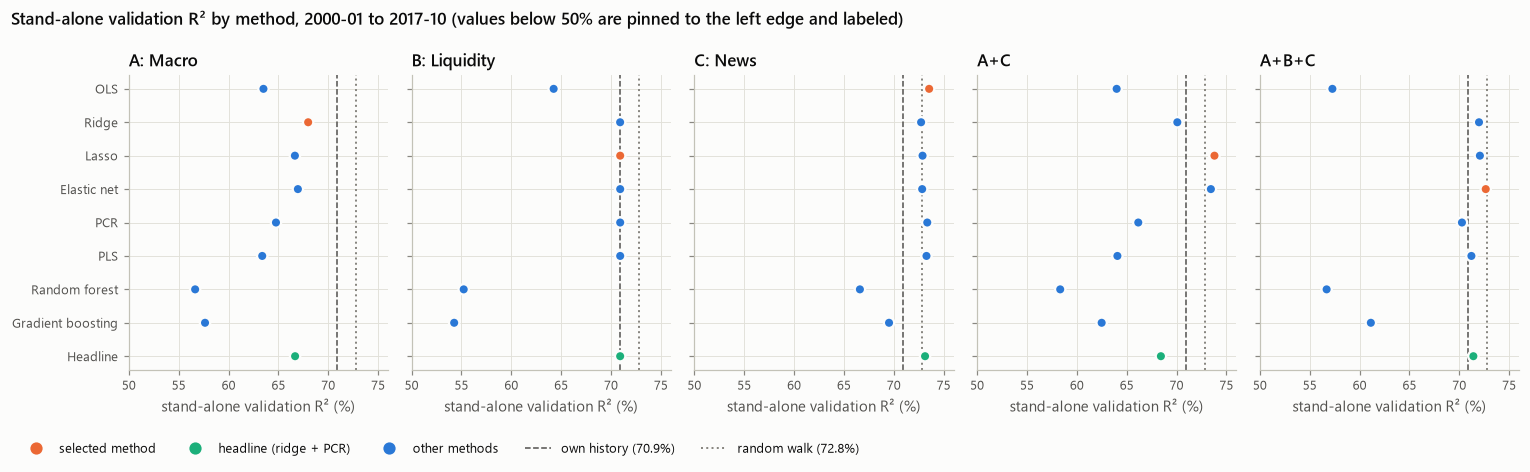

In [10]:
# Stand-alone validation R2 by method. Dots, not bars: the axis starts near 50%, where every model already is.
FIG_SETS = ["A", "B", "C", "A+C", "A+B+C"]
R2_FLOOR = 50
own_r2 = bench_tab.loc["Own history", "R2 vs hist. mean (%)"]
rw_r2 = bench_tab.loc["Trailing correlation", "R2 vs hist. mean (%)"]
fig, axes = plt.subplots(1, len(FIG_SETS), figsize=(14, 3.9), sharey=True)
for ax, s in zip(axes, FIG_SETS):
    v = val.loc[s].loc[METHOD_ORDER + ["Headline"], "R2 vs mean (%)"]
    colors = [PALETTE[1] if m == SELECTED[s] else (PALETTE[2] if m == "Headline" else PALETTE[0]) for m in v.index]
    ax.axvline(own_r2, color=INK2, linestyle="--", linewidth=1, zorder=1)
    ax.axvline(rw_r2, color=MUTED, linestyle=":", linewidth=1.3, zorder=1)
    ax.scatter(v.clip(lower=R2_FLOOR + 0.5), range(len(v)), s=46, c=colors, edgecolors=SURFACE, linewidths=1.5, zorder=3)
    for i, x in enumerate(v):
        if x < R2_FLOOR + 0.5:
            ax.text(R2_FLOOR + 1.3, i, f"{x:.0f}", va="center", fontsize=7.5, color=INK2)
    ax.set_yticks(range(len(v)), v.index)
    ax.invert_yaxis()
    ax.set_xlim(R2_FLOOR, max(76, v.max() + 1.5))
    ax.set_title(s if len(SETS[s]) > 1 else f"{s}: {GROUP_NAMES[s]}")
    ax.set_xlabel("stand-alone validation R² (%)")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=PALETTE[1], label="selected method"),
           plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=PALETTE[2], label="headline (ridge + PCR)"),
           plt.Line2D([], [], marker="o", linestyle="", markersize=7, color=PALETTE[0], label="other methods"),
           plt.Line2D([], [], color=INK2, linestyle="--", linewidth=1, label=f"own history ({own_r2:.1f}%)"),
           plt.Line2D([], [], color=MUTED, linestyle=":", linewidth=1.3, label=f"random walk ({rw_r2:.1f}%)")]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.01, 0.0), ncol=5)
fig.suptitle(f"Stand-alone validation R² by method, 2000-01 to 2017-10 (values below {R2_FLOOR}% are pinned to the "
             "left edge and labeled)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "fig_validation_r2_by_method")
plt.show()


A      B     C    A+B   A+C   B+C  A+B+C
method      share of refits choosing                                             
Ridge       own-history end (%)       22.0  100.0   0.0   61.0   6.0  22.0   11.0
            least-shrinkage end (%)    0.0    0.0  11.0    0.0   0.0   0.0    0.0
Lasso       own-history end (%)       61.0  100.0   6.0   78.0   6.0  11.0   22.0
            least-shrinkage end (%)    0.0    0.0  11.0    0.0   0.0   0.0    0.0
Elastic net own-history end (%)       44.0  100.0   0.0   61.0   0.0  11.0   17.0
            least-shrinkage end (%)    0.0    0.0  11.0    0.0   0.0   0.0    0.0
PCR         own-history end (%)       22.0  100.0   0.0   78.0   6.0  39.0   28.0
            least-shrinkage end (%)    0.0    0.0   6.0    0.0   6.0   0.0    0.0
PLS         own-history end (%)       78.0  100.0  17.0  100.0  22.0  56.0   83.0
            least-shrinkage end (%)    0.0    0.0   6.0    0.0   0.0   0.0    0.0

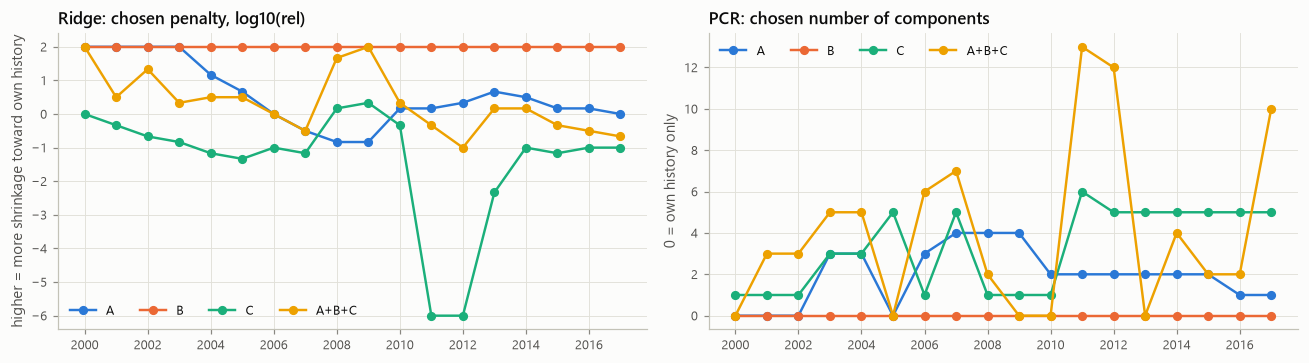

In [11]:
# Hyperparameters chosen at each refit: how aggressive were the models over time?
# Grid ends: the "own-history end" (max penalty / k = 0) means "this set adds nothing", which is a legitimate
# answer, not a grid problem. Hitting the OTHER end (least shrinkage / all components) would suggest the grid
# is too narrow. Any widening must be decided on validation evidence, before the test.
def grid_ends(s, m):
    k, n = INFO[(s, m)]["k"].to_numpy(), INFO[(s, m)]["grid_size"].iloc[0]
    if m == "Ridge":
        own, other = k == n - 1, k == 0
    elif m in ("Lasso", "Elastic net"):
        j = k % len(ENET_REL_GRID)
        own, other = j == 0, j == len(ENET_REL_GRID) - 1
    else:                                    # PCR / PLS
        own, other = k == 0, k == n - 1
    return 100 * own.mean(), 100 * other.mean()


ends = {}
for m in ["Ridge", "Lasso", "Elastic net", "PCR", "PLS"]:
    for s in SETS:
        ends[(m, "own-history end (%)")] = ends.get((m, "own-history end (%)"), {}) | {s: grid_ends(s, m)[0]}
        ends[(m, "least-shrinkage end (%)")] = ends.get((m, "least-shrinkage end (%)"), {}) | {s: grid_ends(s, m)[1]}
ends = pd.DataFrame(ends).T
ends.index.names = ["method", "share of refits choosing"]
display(ends.round(0))
save_table(ends, "table_grid_ends_validation", "{:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for s, c in zip(["A", "B", "C", "A+B+C"], PALETTE):
    axes[0].plot(VAL_YEARS, np.log10(RIDGE_REL_GRID[INFO[(s, "Ridge")]["k"]]), marker="o", color=c, label=s)
    axes[1].plot(VAL_YEARS, INFO[(s, "PCR")]["k"], marker="o", color=c, label=s)      # grid index = components
axes[0].set_title("Ridge: chosen penalty, log10(rel)")
axes[0].set_ylabel("higher = more shrinkage toward own history")
axes[1].set_title("PCR: chosen number of components")
axes[1].set_ylabel("0 = own history only")
for ax in axes:
    ax.legend(ncol=4)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
fig.tight_layout()
save_fig(fig, "fig_hyperparameters_over_time")
plt.show()

## 6. Nested models and group comparisons (validation)

* **Each set vs. own history:** validation $R^2$ and Clark–West, with the selected method and with the headline method.
* **Incremental value:** Clark–West tests of a larger set against each set it nests, e.g. A+B vs. A asks whether liquidity adds to macro. Both forecasts use the headline method so that only the information differs.
* **Group vs. group:** Diebold–Mariano for A vs. B vs. C (headline method and selected method).

In [12]:
y_v = df.loc[val_idx, "y"].to_numpy()
nested = pd.DataFrame({s: {"selected method": SELECTED[s],
                           "R2 vs mean, selected (%)": val.loc[(s, SELECTED[s]), "R2 vs mean (%)"],
                           "R2 vs own, selected (%)": val.loc[(s, SELECTED[s]), "R2 vs own (%)"],
                           "CW p, selected": val.loc[(s, SELECTED[s]), "CW p vs own"],
                           "R2 vs RW, selected (%)": val.loc[(s, SELECTED[s]), "R2 vs RW (%)"],
                           "CW p vs RW, selected": val.loc[(s, SELECTED[s]), "CW p vs RW"],
                           "R2 vs mean, headline (%)": val.loc[(s, "Headline"), "R2 vs mean (%)"],
                           "R2 vs own, headline (%)": val.loc[(s, "Headline"), "R2 vs own (%)"],
                           "CW p, headline": val.loc[(s, "Headline"), "CW p vs own"],
                           "R2 vs RW, headline (%)": val.loc[(s, "Headline"), "R2 vs RW (%)"]} for s in SETS}).T
nested.index.name = "own history +"
display(nested)
save_table(nested, "table_nested_validation", "{:.3f}")

inc = {}
for big in SETS:
    for small in SETS:
        if set(SETS[small]) < set(SETS[big]):
            fs, fb = F[(small, "Headline")].loc[val_idx].to_numpy(), F[(big, "Headline")].loc[val_idx].to_numpy()
            t, p = clark_west(y_v, fs, fb)
            added = "+".join(g for g in SETS[big] if g not in SETS[small])
            inc[f"{big} vs {small}"] = {"adds": f"{added} ({', '.join(GROUP_NAMES[g] for g in added.split('+'))})",
                                        "R2 gain (%)": oos_r2(df.loc[val_idx, "y"], fb, fs), "CW t": t, "CW p": p}
inc = pd.DataFrame(inc).T
inc.index.name = "headline: larger vs nested"
display(inc)
save_table(inc, "table_incremental_validation", "{:.3f}")

dm = {}
for a, b in [("A", "B"), ("A", "C"), ("B", "C")]:
    for meth in ["Headline", "selected"]:
        fa = F[(a, SELECTED[a] if meth == "selected" else meth)].loc[val_idx].to_numpy()
        fb = F[(b, SELECTED[b] if meth == "selected" else meth)].loc[val_idx].to_numpy()
        t, p = diebold_mariano(y_v, fa, fb)
        dm[(f"{a} vs {b}", meth)] = {"DM t (>0: second better)": t, "p": p}
dm = pd.DataFrame(dm).T
dm.index.names = ["comparison", "method"]
display(dm.round(3))
save_table(dm, "table_dm_validation", "{:.3f}")

,selected method,"R2 vs mean, selected (%)","R2 vs own, selected (%)","CW p, selected","R2 vs RW, selected (%)","CW p vs RW, selected","R2 vs mean, headline (%)","R2 vs own, headline (%)","CW p, headline","R2 vs RW, headline (%)"
own history +,,,,,,,,,,
A,Ridge,67.987,-10.098,0.054,-17.796,0.006,66.678,-14.601,0.039,-22.614
B,Lasso,70.923,0.0,NaN,-6.992,0.011,70.92,-0.011,0.954,-7.003
C,OLS,73.551,9.035,0.0,2.675,0.0,73.141,7.625,0.001,1.166
A+B,Elastic net,71.341,1.435,0.042,-5.456,0.006,71.25,1.123,0.053,-5.791
A+C,Lasso,73.806,9.914,0.0,3.615,0.0,68.435,-8.558,0.006,-16.148
B+C,PLS,72.212,4.433,0.011,-2.248,0.002,72.124,4.128,0.016,-2.575
A+B+C,Elastic net,72.655,5.956,0.003,-0.62,0.002,71.413,1.684,0.063,-5.19


,adds,R2 gain (%),CW t,CW p
headline: larger vs nested,,,,
A+B vs A,B (Liquidity),13.72,2.165,0.015
A+B vs B,A (Macro),1.133,1.633,0.051
A+C vs A,C (News),5.273,2.697,0.004
A+C vs C,A (Macro),-17.519,1.237,0.108
B+C vs B,C (News),4.138,2.152,0.016
B+C vs C,B (Liquidity),-3.786,-0.285,0.612
A+B+C vs A,"B+C (Liquidity, News)",14.21,2.267,0.012
A+B+C vs B,"A+C (Macro, News)",1.695,1.534,0.063
A+B+C vs C,"A+B (Macro, Liquidity)",-6.431,-0.095,0.538


DM t (>0: second better)      p
comparison method                                   
A vs B     Headline                     1.724  0.085
           selected                     1.709  0.087
A vs C     Headline                     2.376  0.017
           selected                     2.489  0.013
B vs C     Headline                     1.526  0.127
           selected                     1.554  0.120

## 7. Accuracy-weighted combination of the three groups

At each forecast month $t$ the combination weights each group's forecast (own history + that group) by the inverse of its MSE over the last 36 **realized** forecast errors. Row $s$'s error is known only once its target ends (month $s+3$), so the weights at $t$ use rows up to $t-3$. Weights are equal until 12 errors exist. The window (36) and minimum (12) are fixed here and never tuned. The combination is built from the selected method of each group and, as the method check, from the headline method.

R2 vs mean (%)  R2 vs own (%)  R2 vs RW (%)  sign (%)  CW p vs own  CW p vs RW
Combination selected          72.659          5.969        -0.605    78.972        0.000       0.001
            Headline          72.306          4.753        -1.906    78.505        0.001       0.001

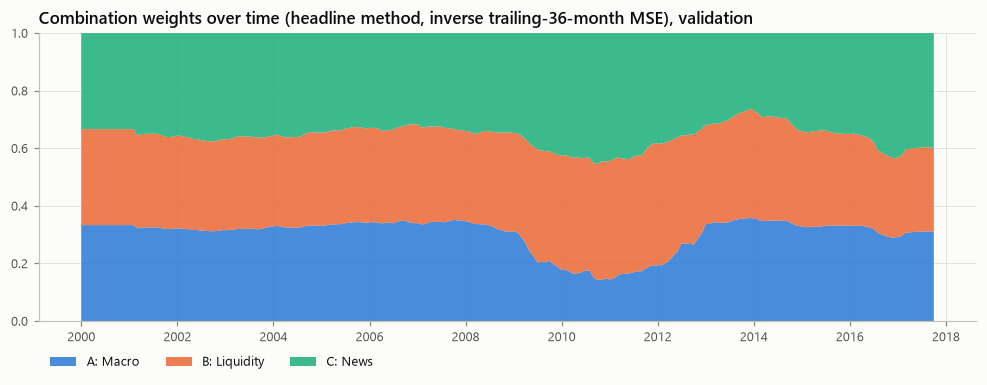

In [13]:
def combine(fc, y):
    """fc: DataFrame of group forecasts (contiguous months). Returns (combined forecast, weights)."""
    err2 = (fc.sub(y, axis=0)) ** 2
    W = pd.DataFrame(np.nan, index=fc.index, columns=fc.columns)
    for i in range(len(fc)):
        past = err2.iloc[max(0, i - 3 - COMB_WINDOW + 1): max(0, i - 2)]      # rows i-3-35 .. i-3 (realized)
        W.iloc[i] = (1 / past.mean()) / (1 / past.mean()).sum() if len(past) >= COMB_MIN else 1 / fc.shape[1]
    return (W * fc).sum(axis=1), W


def combo_forecasts(idx):
    out = {}
    for meth in ["selected", "Headline"]:
        fc = pd.DataFrame({g: F[(g, SELECTED[g] if meth == "selected" else meth)] for g in "ABC"}).loc[idx]
        out[meth] = combine(fc, df.loc[idx, "y"])
    return out


combo_idx = F[("A", "Headline")].index          # all validation forecasts (weights only use realized errors)
COMBO = combo_forecasts(combo_idx)
for meth, (f, W) in COMBO.items():
    F[("Combination", meth)] = f
val_combo = score([("Combination", "selected"), ("Combination", "Headline")], val_idx,
                  F[("bench", "Own history")], F[("bench", "Historical mean")])
display(val_combo.round(3))

fig, ax = plt.subplots(figsize=(11, 3.4))
W = COMBO["Headline"][1].loc[val_idx]
ax.stackplot(W.index.to_timestamp(), W.T.to_numpy(), labels=[f"{g}: {GROUP_NAMES[g]}" for g in W.columns],
             colors=PALETTE[:3], alpha=0.85)
ax.set_ylim(0, 1)
ax.set_title("Combination weights over time (headline method, inverse trailing-36-month MSE), validation")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
save_fig(fig, "fig_combination_weights_validation")
plt.show()

In [14]:
# ---- Freeze the design. Everything the test run uses is written here, before any test forecast exists. ----
FROZEN = {"selected_method": SELECTED, "headline": "equal-weight Ridge + PCR",
          "windows": {"burn-in": "1987-01..1999-12", "validation (scored)": f"2000-01..{VAL_SCORE_END}",
                      "test": "2018-01..2025-09"},
          "refit": "yearly expanding; fit rows 1987-01..(Y-1)-10; hyperparameters re-tuned by purged blocked 5-fold CV",
          "combination": {"window": COMB_WINDOW, "min_errors": COMB_MIN},
          "grids": {"ridge_rel": [RIDGE_REL_GRID.min(), RIDGE_REL_GRID.max(), len(RIDGE_REL_GRID)],
                    "enet_rel": [ENET_REL_GRID.min(), ENET_REL_GRID.max(), len(ENET_REL_GRID)],
                    "enet_l1": ENET_L1_GRID, "rf": RF_GRID, "rf_trees": RF_TREES, "gb": GB_GRID,
                    "gb_max_trees": GB_MAX_TREES},
          "frozen_at": pd.Timestamp.now().isoformat(timespec="seconds")}
path = OUT / "frozen_design.json"
if not RUN_TEST:
    path.write_text(json.dumps(FROZEN, indent=2, default=str), encoding="utf-8")
    print(f"Design written to {path}")
else:
    saved = json.loads(path.read_text(encoding="utf-8"))
    assert saved["selected_method"] == SELECTED, "validation selections changed since the design was frozen"
    print(f"Test run: using the design frozen at {saved['frozen_at']}")
print(json.dumps(FROZEN["selected_method"], indent=1))

Test run: using the design frozen at 2026-11-13T14:44:48
{
 "A": "Ridge",
 "B": "Lasso",
 "C": "OLS",
 "A+B": "Elastic net",
 "A+C": "Lasso",
 "B+C": "PLS",
 "A+B+C": "Elastic net"
}


## 8. What drives the best models (validation)

The two best validation models are **news (C) with OLS** and **macro + news (A+C) with the lasso** (Table 2). This section opens them up. It is descriptive only: nothing here feeds back into the design, which was frozen in the cell above.

* Each yearly refit (2000 to 2017) is rebuilt with the hyperparameter that cross-validation chose at the time, and the cell checks that the rebuilt coefficients reproduce every scored forecast exactly.
* **Coefficients are standardized:** the change in the forecast correlation per 1 sd move in the predictor, after removing the part of the predictor the trailing correlation already explains. This is the scale the penalties act on, so OLS and lasso coefficients are directly comparable. A positive coefficient pushes the forecast toward a *more positive* stock-bond correlation.
* **Contributions** are coefficient × (residualized) predictor in each month. Their sum is exactly the model's forecast minus the own-history forecast, so they show *when* and *through which variable* the model departed from own history.


In [15]:
# ---- What drives the best models: coefficients at every refit ----
COEF_MODELS = {"C": SELECTED["C"], "A+C": SELECTED["A+C"]}
assert COEF_MODELS == {"C": "OLS", "A+C": "Lasso"}, "the discussion below is written for C/OLS and A+C/Lasso"


def refit_coefs(s, mname):
    """Rebuild every yearly refit of (s, mname) with the hyperparameter CV chose (stored in INFO) and return
    (standardized coefficients, raw-unit coefficients, monthly contributions). Standardized = per 1 sd of the
    predictor after partialling out the trailing correlation, the scale the penalties act on. A contribution is
    coefficient x residualized predictor; the contributions of a month sum to forecast minus own history."""
    cols = set_cols(s)
    std, raw, contrib = {}, {}, []
    for Y in VAL_YEARS:
        k = int(INFO[(s, mname)].loc[Y, "k"])
        fit = fit_rows(df, Y)
        ev = df.loc[pd.Period(f"{Y}-01", "M"): min(pd.Period(f"{Y}-12", "M"), VAL_END)]
        X, h, y = fit[cols].to_numpy(float), fit["h"].to_numpy(float), fit["y"].to_numpy(float)
        Z, Z_e, r, base = partial_out(X, h, y, ev[cols].to_numpy(float), ev["h"].to_numpy(float))
        if mname == "OLS":
            beta = np.linalg.lstsq(Z, r, rcond=None)[0]           # Frisch-Waugh: same slopes as the full OLS
        elif mname == "Lasso":
            amax = np.abs(Z.T @ r).max() / len(r)
            beta = enet_path(Z, r, l1_ratio=1.0, alphas=amax * ENET_REL_GRID, max_iter=5000)[1][:, k]
        else:
            raise ValueError(mname)
        # the coefficients must reproduce the forecasts that were scored
        assert np.allclose(base + Z_e @ beta, F[(s, mname)].loc[ev.index], atol=1e-8), (s, mname, Y)
        H = _design(h)
        b, G = np.linalg.lstsq(H, y, rcond=None)[0], np.linalg.lstsq(H, X, rcond=None)[0]
        sd = (X - H @ G).std(axis=0)
        sd[sd == 0] = 1.0
        std[Y] = pd.Series(beta, index=cols)
        raw[Y] = pd.Series(np.r_[b - G @ (beta / sd), beta / sd], index=["intercept", "trailing corr"] + cols)
        contrib.append(pd.DataFrame(Z_e * beta, index=ev.index, columns=cols))
    return pd.DataFrame(std).T, pd.DataFrame(raw).T, pd.concat(contrib)


COEFS = {s: refit_coefs(s, m) for s, m in COEF_MODELS.items()}

rows = {}
for s, m in COEF_MODELS.items():
    B = COEFS[s][0]
    nz = B != 0
    modal = np.sign(B.where(nz).sum())
    for c in B.columns:
        rows[(f"{s} ({m})", c)] = {
            "refits selected (of 18)": int(nz[c].sum()),
            "mean coef per sd": B[c].mean(),
            "same sign (% of selected)": (100 * ((np.sign(B[c]) == modal[c]) & nz[c]).sum() / nz[c].sum()
                                          if nz[c].any() else np.nan),
            "coef per sd, 2017 refit": B.loc[2017, c],
            "mean |contribution|": COEFS[s][2].loc[val_idx, c].abs().mean()}
coef_tab = pd.DataFrame(rows).T
coef_tab.index.names = ["model", "predictor"]
print("Coefficients of the two best models across the 18 validation refits (2000-2017). Coefficients are per 1 sd "
      "of the predictor after partialling out the trailing correlation; a positive sign pushes the forecast "
      "correlation up (toward positive). Mean |contribution| = average absolute shift of the forecast vs. own history.")
display(coef_tab.round(3))
save_table(coef_tab, "table_coefs_selected_validation", "{:.3f}")
print("Trailing-correlation slope and intercept (raw units) in the full model, every 3rd refit:")
display(pd.concat({f"{s} ({m})": COEFS[s][1][["intercept", "trailing corr"]].iloc[::3].T
                   for s, m in COEF_MODELS.items()}).round(3))


Coefficients of the two best models across the 18 validation refits (2000-2017). Coefficients are per 1 sd of the predictor after partialling out the trailing correlation; a positive sign pushes the forecast correlation up (toward positive). Mean |contribution| = average absolute shift of the forecast vs. own history.


refits selected (of 18)  mean coef per sd  same sign (% of selected)  coef per sd, 2017 refit  mean |contribution|
model       predictor                                                                                                                               
C (OLS)     epu_overall                              18.0             0.052                    100.000                    0.032                0.049
            epu_monetary                             18.0            -0.011                     66.667                    0.010                0.012
            emv_inflation_share                      18.0             0.050                    100.000                    0.048                0.043
            emv_rates_share                          18.0             0.071                    100.000                    0.086                0.062
            emv_monetary_share                       18.0            -0.048                    100.000                   -0.072                0.047
            emv_macro_news_share                     18.0            -0.027                    100.000                   -0.026                0.028
A+C (Lasso) infl_yoy                                  2.0             0.000                    100.000                   -0.000                0.000
            infl_vol12                                5.0            -0.003                    100.000                   -0.000                0.009
            exp_infl_mich                             5.0             0.003                     80.000                   -0.002                0.002
            unemp_chg12                              11.0            -0.006                    100.000                   -0.003                0.006
            tbill                                    11.0             0.018                    100.000                    0.047                0.017
            term_spread                               1.0             0.000                    100.000                    0.000                0.000
            epu_overall                              11.0             0.014                    100.000                    0.025                0.012
            epu_monetary                              0.0             0.000                        NaN                    0.000                0.000
            emv_inflation_share                      12.0             0.012                    100.000                    0.022                0.010
            emv_rates_share                          17.0             0.036                    100.000                    0.068                0.029
            emv_monetary_share                        8.0            -0.018                    100.000                   -0.050                0.017
            emv_macro_news_share                      3.0            -0.000                     66.667                   -0.000                0.000

Trailing-correlation slope and intercept (raw units) in the full model, every 3rd refit:


2000   2003   2006   2009   2012   2015
C (OLS)     intercept      0.352 -0.470 -0.437 -0.116 -0.040 -0.106
            trailing corr  0.373  0.543  0.525  0.563  0.594  0.586
A+C (Lasso) intercept      0.113 -0.094 -0.432 -0.055 -0.299 -0.354
            trailing corr  0.490  0.733  0.459  0.738  0.565  0.582

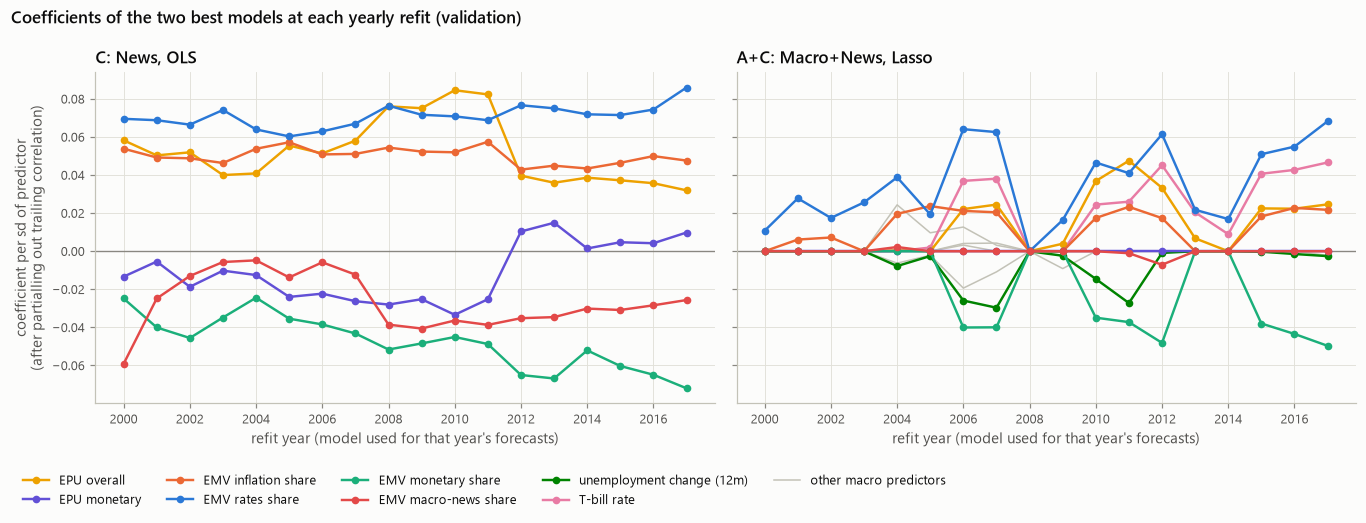

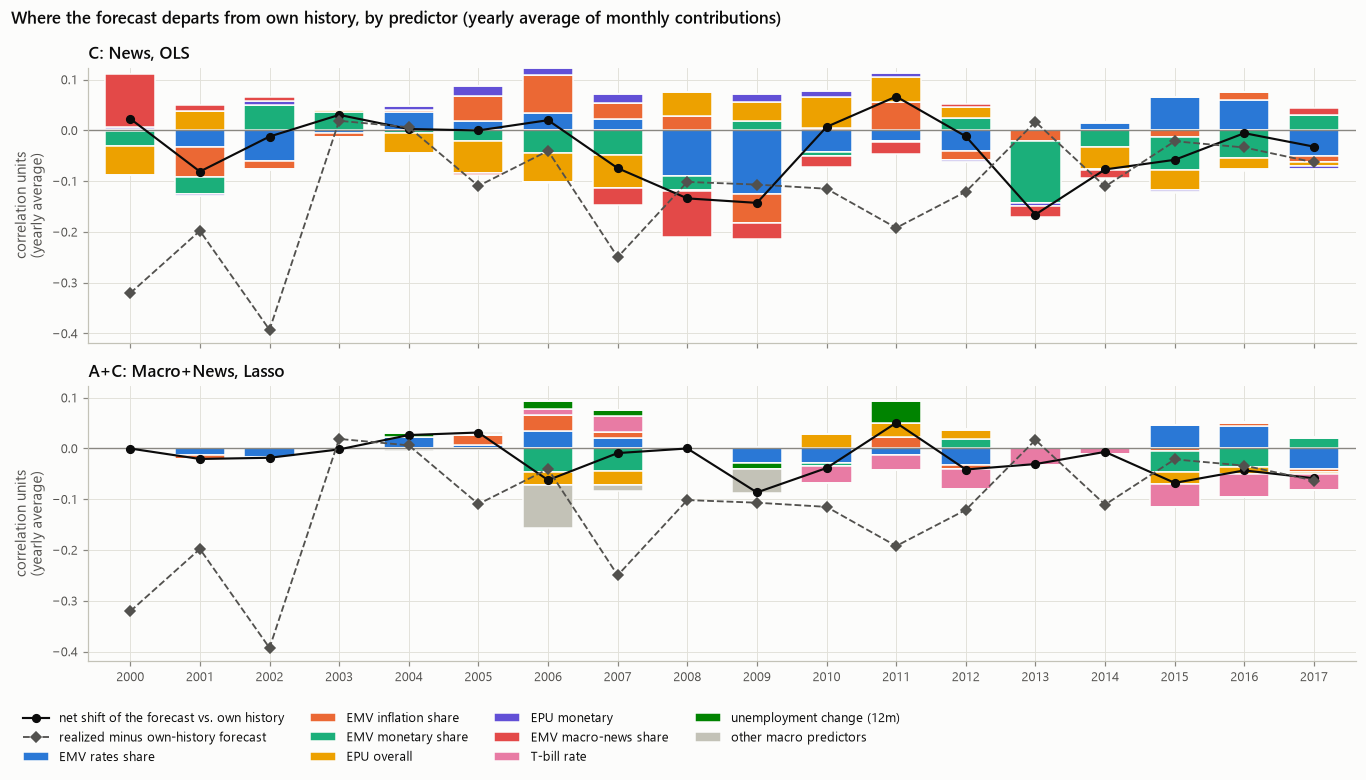

In [16]:
# One fixed color per predictor, shared by both panels and both figures (color follows the variable).
VAR_LABEL = {"emv_rates_share": "EMV rates share", "emv_inflation_share": "EMV inflation share",
             "emv_monetary_share": "EMV monetary share", "emv_macro_news_share": "EMV macro-news share",
             "epu_overall": "EPU overall", "epu_monetary": "EPU monetary", "tbill": "T-bill rate",
             "unemp_chg12": "unemployment change (12m)", "infl_yoy": "inflation (yoy)",
             "infl_vol12": "inflation volatility", "exp_infl_mich": "expected inflation (Mich.)",
             "term_spread": "term spread"}
KEY_VARS = ["emv_rates_share", "emv_inflation_share", "emv_monetary_share", "epu_overall", "tbill", "unemp_chg12",
            "epu_monetary", "emv_macro_news_share"]
VAR_COLOR = dict(zip(KEY_VARS, PALETTE))
OTHER_COLOR = AXIS


def merged_legend(fig, axes, extra=(), **kw):
    h, l = [], []
    for ax in axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l and not ll.startswith("_"):
                h.append(hh); l.append(ll)
    for hh, ll in extra:
        h.append(hh); l.append(ll)
    fig.legend(h, l, **kw)


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, (s, m) in zip(axes, COEF_MODELS.items()):
    B = COEFS[s][0]
    for c in sorted(B.columns, key=lambda c: c in VAR_COLOR):             # grey lines first, colored on top
        if c in VAR_COLOR:
            ax.plot(B.index, B[c], color=VAR_COLOR[c], marker="o", markersize=4, label=VAR_LABEL[c])
        else:
            ax.plot(B.index, B[c], color=OTHER_COLOR, linewidth=1, label="_other")
    zero_line(ax)
    ax.set_title(f"{s}: {'+'.join(GROUP_NAMES[g] for g in SETS[s])}, {m}")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(2))
    ax.set_xlabel("refit year (model used for that year's forecasts)")
axes[0].set_ylabel("coefficient per sd of predictor\n(after partialling out trailing correlation)")
merged_legend(fig, axes, [(plt.Line2D([], [], color=OTHER_COLOR, linewidth=1), "other macro predictors")],
              loc="upper left", bbox_to_anchor=(0.01, 0.0), ncol=5)
fig.suptitle("Coefficients of the two best models at each yearly refit (validation)", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "fig_coefs_over_time_validation")
plt.show()

# Contributions: how far, and in which direction, each predictor moved the forecast away from own history.
fig, axes = plt.subplots(2, 1, figsize=(12.5, 6.4), sharex=True, sharey=True)
gap = (df.loc[val_idx, "y"] - F[("bench", "Own history")].loc[val_idx]).groupby(val_idx.year).mean()
for ax, (s, m) in zip(axes, COEF_MODELS.items()):
    Cb = COEFS[s][2].loc[val_idx]
    Cb = pd.concat([Cb[[c for c in KEY_VARS if c in Cb.columns]],
                    Cb[[c for c in Cb.columns if c not in VAR_COLOR]].sum(axis=1).rename("other")], axis=1)
    Cb = Cb.loc[:, (Cb != 0).any()]
    A = Cb.groupby(Cb.index.year).mean()
    pos, neg = np.zeros(len(A)), np.zeros(len(A))
    for c in A.columns:
        v = A[c].to_numpy()
        col, lab = VAR_COLOR.get(c, OTHER_COLOR), VAR_LABEL.get(c, "other macro predictors")
        up, dn = np.where(v > 0, v, 0), np.where(v < 0, v, 0)
        ax.bar(A.index, up, bottom=pos, color=col, width=0.72, edgecolor=SURFACE, linewidth=1, label=lab)
        ax.bar(A.index, dn, bottom=neg, color=col, width=0.72, edgecolor=SURFACE, linewidth=1)
        pos += up
        neg += dn
    ax.plot(A.index, A.sum(axis=1), color=INK, marker="o", markersize=5, linewidth=1.4,
            label="net shift of the forecast vs. own history")
    ax.plot(gap.index, gap, color=INK2, marker="D", markersize=5, linewidth=1.2, linestyle="--",
            label="realized minus own-history forecast")
    zero_line(ax)
    ax.set_title(f"{s}: {'+'.join(GROUP_NAMES[g] for g in SETS[s])}, {m}")
    ax.set_ylabel("correlation units\n(yearly average)")
    ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
    ax.set_xlim(VAL_YEARS[0] - 0.6, VAL_YEARS[-1] + 0.6)
merged_legend(fig, axes, loc="upper left", bbox_to_anchor=(0.01, 0.0), ncol=4)
fig.suptitle("Where the forecast departs from own history, by predictor (yearly average of monthly contributions)",
             x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "fig_coef_contributions_validation")
plt.show()


### Reading the coefficients

**What the models select.**
* **News with OLS.** All six news variables enter at every refit, and five of them keep the same sign in all 18 refits:
  * the EMV rates share (about +0.07 per sd), the EMV inflation share (+0.05) and overall EPU (+0.05) push the forecast up;
  * the EMV monetary-policy share (−0.05) and the EMV macro-news share (−0.03) push it down;
  * monetary EPU is small and flips sign in 2012. It is highly correlated with overall EPU (0.78), so the two split one effect between them.
* **Macro + news with the lasso.**
  * The **EMV rates share** is kept in 17 of 18 refits. The inflation share, the T-bill rate, overall EPU and the 12-month change in unemployment are kept in about two-thirds of them, and the monetary share in eight.
  * The other macro variables (inflation, inflation volatility, expected inflation, the term spread) rarely survive.
  * In the 2008 refit cross-validation dropped everything, so 2008 forecasts equal own history.
  * The lasso keeps the same news signal as OLS, with the same signs, but shrinks it heavily (the rates-share coefficient averages about half its OLS size), and adds the T-bill rate and unemployment.

**Why these variables help: which shock dominates.** The sign of the stock-bond correlation depends on what is moving markets:
* When discount-rate and inflation shocks dominate, higher rates or inflation hurt stocks and bonds together, and the correlation is positive. This was the 1970s–1990s "inflation bets" regime (Campbell, Sunderam and Viceira, 2017; David and Veronesi, 2013).
* When growth and risk shocks dominate, bad news sends investors from stocks into Treasuries, and the correlation is negative: flight to quality, the post-2000 regime (Baele, Bekaert and Inghelbrecht, 2010).

The selected variables measure, in real time, which kind of shock the market is paying attention to:
* **EMV rates and inflation shares (+).** They measure the share of newspaper coverage of equity-market moves that is about interest rates or inflation. A high share means discount-rate news is driving stocks, which is exactly when stocks and bonds move together. The two shares are correlated (0.71) and enter with the same sign, so they are best read as one "rates and inflation are what matter" signal.
* **EMV monetary-policy share (−).** Holding rate and inflation news fixed, more coverage of the Fed itself (crisis lending, QE, forward guidance) marks periods when the central bank is easing into bad news. Then Treasuries hedge equity risk and the correlation is more negative.
* **T-bill rate (+).** Its positive coefficient matters mostly through its *level*: near zero from 2009, it pulled forecasts down in every year from 2010 to 2017, by about 0.03–0.045 in most of them. That partly corrects the own-history model, whose intercept is anchored by the positive-correlation 1990s and so sits too high. Near the zero lower bound, growth and risk shocks dominate and the hedging property of Treasuries is strongest.
* **Change in unemployment (−).** Rising unemployment signals growth shocks and flight to quality, so a more negative correlation.
* **EMV macro-news share (−, OLS only).** More macro (largely growth) news in market commentary also points toward the flight-to-quality regime.
* **Overall EPU (+).** This is the hardest sign to rationalize. High policy uncertainty would usually be expected to strengthen flight to quality. In 2008–2011 its contribution pushed forecasts the wrong way, up while realized correlations came in below own history. One possibility is mean reversion after crisis-level negative correlations, but it should not be presented as a finding.

**How much the predictors actually move the forecast.**
* The effects are small. The largest coefficient is about 0.07 per sd, against a target sd of about 0.54. The net shift away from own history is usually under ±0.1, and it is positively but weakly correlated with the own-history model's miss (about 0.2 month by month).
* The models do **not** anticipate the big misses of 2000–2002, when the correlation turned negative: no variable signalled the regime change in advance. Their gains come from steady, mid-sized corrections in the right direction, e.g. 2007–2009 for news with OLS and 2012 and 2015–2017 for both models.
* That matches the stand-alone $R^2$ in Table 2: persistence explains about 71% of the variance, and news adds a few points on top.

**Caveats.**
* These are conditional, correlated and non-causal coefficients. Each sign is "holding the trailing correlation and the other variables fixed."
* Both models were chosen *because* they did well on validation, so their validation fit is optimistic. Only the test window can show whether the news signal is real.


## 9. Robustness (validation window only, so the test stays untouched)

1. **WSJ topics (group D) in place of news (C).** The WSJ data end in 2017-06, so this comparison uses validation rows 2000-01 to 2017-06, and C is re-scored on the same months.
2. **5- and 30-year Treasuries** in place of the 10-year: target, trailing correlation and own-history benchmark all rebuilt for that maturity.
3. **Rolling 15-year window** instead of expanding.
4. **Appendix: univariate models**, own history + one predictor at a time (OLS).

Robustness runs use the headline method (and, for D, also the method selected for C), so they do not add selection on top of the main analysis.

In [17]:
with timer("robustness: WSJ"):
    wsj_end = min(df[GROUPS["D"]].dropna().index[-1], VAL_END)        # WSJ data end 2017-06
    idx_d = df.loc[pd.Period("2000-01", "M"):min(wsj_end, VAL_SCORE_END)].index
    run(("D", "Ridge"), Ridge(), GROUPS["D"], end=wsj_end)
    run(("D", "PCR"), PCR(6), GROUPS["D"], end=wsj_end)
    run(("D", SELECTED["C"]), methods_for(6)[SELECTED["C"]], GROUPS["D"], end=wsj_end)
    F[("D", "Headline")] = (F[("D", "Ridge")] + F[("D", "PCR")]) / 2
    run(("bench_d", "Own history"), OwnHistory(), [], end=wsj_end)
    run(("bench_d", "Historical mean"), HistMean(), [], end=wsj_end)
rob_wsj = score([("C", "Headline"), ("D", "Headline"), ("C", SELECTED["C"]), ("D", SELECTED["C"])], idx_d,
                F[("bench_d", "Own history")], F[("bench_d", "Historical mean")])
rob_wsj.index = [f"{GROUP_NAMES[s]} ({m})" for s, m in rob_wsj.index]
rob_wsj.index.name = f"2000-01 to {wsj_end}"
display(rob_wsj.round(3))
save_table(rob_wsj, "table_robustness_wsj", "{:.3f}")

[robustness: WSJ: 0.2s]


,R2 vs mean (%),R2 vs own (%),R2 vs RW (%),sign (%),CW p vs own,CW p vs RW
2000-01 to 2017-06,,,,,,
News (Headline),73.261,7.492,0.772,77.619,0.002,0.000
WSJ topics (Headline),69.119,-6.837,-14.597,80.952,0.006,0.007
News (OLS),73.680,8.941,2.327,80.952,0.000,0.000
WSJ topics (OLS),67.902,-11.048,-19.113,81.429,0.003,0.003


In [18]:
rob_mat = {}
with timer("robustness: 5Y and 30Y Treasuries"):
    for mat in ["5Y", "30Y"]:
        d_m = df.copy()
        d_m["y"], d_m["h"] = targets[mat][0].loc[df.index], targets[mat][1].loc[df.index]
        own = recursive_forecasts(OwnHistory(), d_m, [], VAL_YEARS, VAL_END)[0]
        mean = recursive_forecasts(HistMean(), d_m, [], VAL_YEARS, VAL_END)[0]
        for s in ["A", "B", "C", "A+B+C"]:
            cols = set_cols(s)
            f = (recursive_forecasts(Ridge(), d_m, cols, VAL_YEARS, VAL_END)[0]
                 + recursive_forecasts(PCR(len(cols)), d_m, cols, VAL_YEARS, VAL_END)[0]) / 2
            y_, rw = d_m.loc[val_idx, "y"], d_m.loc[val_idx, "h"]
            rob_mat[(mat, s)] = {"R2 vs mean (%)": oos_r2(y_, f.loc[val_idx], mean.loc[val_idx]),
                                 "R2 vs own (%)": oos_r2(y_, f.loc[val_idx], own.loc[val_idx]),
                                 "CW p vs own": clark_west(y_.to_numpy(), own.loc[val_idx].to_numpy(), f.loc[val_idx].to_numpy())[1],
                                 "R2 vs RW (%)": oos_r2(y_, f.loc[val_idx], rw),
                                 "own R2 vs mean (%)": oos_r2(y_, own.loc[val_idx], mean.loc[val_idx]),
                                 "own R2 vs RW (%)": oos_r2(y_, own.loc[val_idx], rw)}
    for s in ["A", "B", "C", "A+B+C"]:
        rob_mat[("10Y", s)] = {"R2 vs mean (%)": val.loc[(s, "Headline"), "R2 vs mean (%)"],
                               "R2 vs own (%)": val.loc[(s, "Headline"), "R2 vs own (%)"],
                               "CW p vs own": val.loc[(s, "Headline"), "CW p vs own"],
                               "R2 vs RW (%)": val.loc[(s, "Headline"), "R2 vs RW (%)"],
                               "own R2 vs mean (%)": bench_tab.loc["Own history", "R2 vs hist. mean (%)"],
                               "own R2 vs RW (%)": oos_r2(yv, own_v, df.loc[val_idx, "h"])}
rob_mat = pd.DataFrame(rob_mat).T.sort_index(level=0, key=lambda i: i.map({"5Y": 0, "10Y": 1, "30Y": 2}))
rob_mat.index.names = ["maturity", "own history + (headline)"]
display(rob_mat.round(3))
save_table(rob_mat, "table_robustness_maturity", "{:.3f}")

[robustness: 5Y and 30Y Treasuries: 0.9s]


R2 vs mean (%)  R2 vs own (%)  CW p vs own  R2 vs RW (%)  own R2 vs mean (%)  own R2 vs RW (%)
maturity own history + (headline)                                                                                                
5Y       A                                 63.757        -15.721        0.049       -20.108              68.680            -3.791
         A+B+C                             68.834          0.491        0.102        -3.281              68.680            -3.791
         B                                 68.677         -0.011        0.934        -3.802              68.680            -3.791
         C                                 71.765          9.850        0.000         6.432              68.680            -3.791
10Y      A                                 66.678        -14.601        0.039       -22.614              70.923            -6.992
         A+B+C                             71.413          1.684        0.063        -5.190              70.923            -6.992
         B                                 70.920         -0.011        0.954        -7.003              70.923            -6.992
         C                                 73.141          7.625        0.001         1.166              70.923            -6.992
30Y      A                                 69.253        -13.826        0.043       -22.366              72.988            -7.503
         A+B+C                             73.948          3.554        0.020        -3.683              72.988            -7.503
         B                                 72.985         -0.012        0.938        -7.516              72.988            -7.503
         C                                 75.492          9.269        0.001         2.461              72.988            -7.503

In [19]:
rob_roll = {}
with timer("robustness: rolling 15-year window"):
    own_r = recursive_forecasts(OwnHistory(), df, [], VAL_YEARS, VAL_END, window=ROLL_YEARS)[0]
    for s in ["A", "B", "C", "A+B+C"]:
        cols = set_cols(s)
        f = (recursive_forecasts(Ridge(), df, cols, VAL_YEARS, VAL_END, window=ROLL_YEARS)[0]
             + recursive_forecasts(PCR(len(cols)), df, cols, VAL_YEARS, VAL_END, window=ROLL_YEARS)[0]) / 2
        rob_roll[s] = {"R2 vs mean (%)": oos_r2(yv, f.loc[val_idx], F[("bench", "Historical mean")].loc[val_idx]),
                       "R2 vs expanding own (%)": oos_r2(yv, f.loc[val_idx], own_v),
                       "R2 vs rolling own (%)": oos_r2(yv, f.loc[val_idx], own_r.loc[val_idx]),
                       "CW p vs rolling own": clark_west(y_v, own_r.loc[val_idx].to_numpy(), f.loc[val_idx].to_numpy())[1],
                       "R2 vs RW (%)": oos_r2(yv, f.loc[val_idx], df.loc[val_idx, "h"]),
                       "expanding, R2 vs own (%)": val.loc[(s, "Headline"), "R2 vs own (%)"]}
rob_roll = pd.DataFrame(rob_roll).T
rob_roll.index.name = "own history + (headline)"
print(f"Rolling own history vs expanding own history: R2 = {oos_r2(yv, own_r.loc[val_idx], own_v):.2f}%; "
      f"rolling own history stand-alone R2 = {oos_r2(yv, own_r.loc[val_idx], F[('bench', 'Historical mean')].loc[val_idx]):.2f}%")
display(rob_roll.round(3))
save_table(rob_roll, "table_robustness_rolling", "{:.3f}")

[robustness: rolling 15-year window: 0.5s]
Rolling own history vs expanding own history: R2 = 8.57%; rolling own history stand-alone R2 = 73.42%


,R2 vs mean (%),R2 vs expanding own (%),R2 vs rolling own (%),CW p vs rolling own,R2 vs RW (%),"expanding, R2 vs own (%)"
own history + (headline),,,,,,
A,63.983,-23.869,-35.487,0.038,-32.529,-14.601
B,71.410,1.674,-7.548,0.422,-5.200,-0.011
C,73.960,10.443,2.043,0.002,4.182,7.625
A+B+C,61.979,-30.763,-43.028,0.053,-39.906,1.684


In [20]:
uni = {}
with timer("appendix: univariate models"):
    for g in "ABCD":
        for c in GROUPS[g]:
            end = VAL_END if g != "D" else wsj_end
            idx = val_idx if g != "D" else idx_d
            ob = F[("bench", "Own history")] if g != "D" else F[("bench_d", "Own history")]
            mb = F[("bench", "Historical mean")] if g != "D" else F[("bench_d", "Historical mean")]
            f = recursive_forecasts(OLS(), df, [c], VAL_YEARS, end)[0]
            y_ = df.loc[idx, "y"]
            last = fit_rows(df, 2017)
            Z = np.column_stack([np.ones(len(last)), last["h"], (last[c] - last[c].mean()) / last[c].std()])
            uni[(GROUP_NAMES[g], c)] = {"R2 vs mean (%)": oos_r2(y_, f.loc[idx], mb.loc[idx]),
                                        "R2 vs own (%)": oos_r2(y_, f.loc[idx], ob.loc[idx]),
                                        "R2 vs RW (%)": oos_r2(y_, f.loc[idx], df.loc[idx, "h"]),
                                        "CW p vs own": clark_west(y_.to_numpy(), ob.loc[idx].to_numpy(), f.loc[idx].to_numpy())[1],
                                        "coef per sd (2017 fit)": np.linalg.lstsq(Z, last["y"], rcond=None)[0][2]}
uni = pd.DataFrame(uni).T
uni.index.names = ["group", "predictor"]
display(uni.round(3))
save_table(uni, "table_appendix_univariate", "{:.3f}")

[appendix: univariate models: 1.1s]


R2 vs mean (%)  R2 vs own (%)  R2 vs RW (%)  CW p vs own  coef per sd (2017 fit)
group      predictor                                                                                               
Macro      infl_yoy                        71.054          0.448        -6.512        0.131                   0.038
           infl_vol12                      68.919         -6.895       -14.369        0.143                  -0.043
           exp_infl_mich                   69.973         -3.268       -10.488        0.608                   0.007
           unemp_chg12                     70.455         -1.610        -8.714        0.084                  -0.028
           tbill                           73.087          7.440         0.968        0.001                   0.097
           term_spread                     69.371         -5.339       -12.704        0.960                  -0.018
Liquidity  credit_spread                   69.269         -5.689       -13.079        0.956                  -0.011
           cp_spread                       70.251         -2.312        -9.465        0.820                   0.022
           vix_monthend                    70.788         -0.464        -7.488        0.775                   0.003
           treasury_noise                  70.533         -1.344        -8.430        0.303                   0.018
           ps_liquidity                    70.884         -0.134        -7.135        0.465                  -0.018
News       epu_overall                     70.884         -0.137        -7.138        0.143                   0.036
           epu_monetary                    71.527          2.076        -4.771        0.026                   0.042
           emv_inflation_share             71.553          2.166        -4.674        0.022                   0.075
           emv_rates_share                 72.199          4.388        -2.296        0.010                   0.081
           emv_monetary_share              70.673         -0.860        -7.912        0.676                  -0.023
           emv_macro_news_share            69.391         -5.272       -12.632        0.642                   0.008
WSJ topics wsj_Federal Reserve             70.351         -2.574       -10.024        0.647                   0.001
           wsj_Recession                   70.685         -1.419        -8.785        0.459                  -0.017
           wsj_Oil market                  70.974         -0.420        -7.714        0.458                  -0.025
           wsj_Treasury bonds              75.280         14.477         8.265        0.000                   0.131
           wsj_Financial crisis            65.402        -19.696       -28.390        0.012                  -0.059
           wsj_Government budgets          68.439         -9.188       -17.119        0.403                   0.032

## 10. Test window, run once (Table 1)

This section runs only when `RUN_TEST = True`. Set it in the setup cell **once**, after the team has agreed the design is final, and rerun the whole notebook. The run:
1. checks that the validation selections still match `output/frozen_design.json`;
2. forecasts 2018-01 to 2025-09 with the same yearly expanding refits and per-refit CV tuning;
3. fills Table 1 and applies the pre-registered decision rule;
4. reports full 2000–2025 results for the headline method only (clean, because nothing about it was chosen on validation);
5. writes timestamped outputs that must not be changed afterwards.

In [21]:
if not RUN_TEST:
    print("RUN_TEST = False: the test window has not been touched. No test forecasts were computed.")
else:
    with timer("test window"):
        run(("bench", "Historical mean"), HistMean(), [], TEST_YEARS, TEST_END)
        run(("bench", "Own history"), OwnHistory(), [], TEST_YEARS, TEST_END)
        for s in SETS:
            cols = set_cols(s)
            for mname in {SELECTED[s], "Ridge", "PCR"}:
                f_val = F[(s, mname)]
                run((s, mname), methods_for(len(cols))[mname], cols, TEST_YEARS, TEST_END)
                F[(s, mname)] = pd.concat([f_val, F[(s, mname)]])          # keep validation forecasts too
            F[(s, "Headline")] = (F[(s, "Ridge")] + F[(s, "PCR")]) / 2
        # benchmarks: rerun over validation + test so the full-period table has them
        for b, m in [("Historical mean", HistMean()), ("Own history", OwnHistory())]:
            run(("bench", b), m, [], VAL_YEARS + TEST_YEARS, TEST_END)
        all_idx = F[("A", "Headline")].index
        COMBO = combo_forecasts(all_idx)              # weights at each month use only realized past errors
        for meth, (f, W) in COMBO.items():
            F[("Combination", meth)] = f

    own_t, mean_t = F[("bench", "Own history")], F[("bench", "Historical mean")]
    y_t = df.loc[test_idx, "y"].to_numpy()
    rows = {"Own history": ("bench", "Own history")}
    for s in ["A", "B", "C", "A+B", "A+B+C"]:
        rows[f"+ {s}"] = (s, SELECTED[s])
    rows["Accuracy-weighted combination"] = ("Combination", "selected")
    for s in ["A", "B", "C", "A+B+C"]:
        rows[f"+ {s}, headline"] = (s, "Headline")
    rows["Combination, headline"] = ("Combination", "Headline")
    t1 = score(list(rows.values()), test_idx, own_t, mean_t)
    t1.index = list(rows)
    t1.insert(0, "method", [k[1] if k[0] != "bench" else "—" for k in rows.values()])
    t1.loc["Own history", ["R2 vs own (%)", "CW p vs own"]] = [0.0, np.nan]
    rw_row = {"method": "—", "R2 vs mean (%)": oos_r2(df.loc[test_idx, "y"], df.loc[test_idx, "h"], mean_t.loc[test_idx]),
              "R2 vs own (%)": oos_r2(df.loc[test_idx, "y"], df.loc[test_idx, "h"], own_t.loc[test_idx]),
              "R2 vs RW (%)": 0.0,
              "sign (%)": sign_acc(df.loc[test_idx, "y"], df.loc[test_idx, "h"]), "CW p vs own": np.nan, "CW p vs RW": np.nan}
    t1 = pd.concat([pd.DataFrame([rw_row], index=["Random walk (trailing correlation)"]), t1])
    t1.index.name = "model (test 2018-01 to 2025-09)"
    display(t1)

    # ---- pre-registered decision rule ----
    def decide(meth_label):
        keys = {g: (g, SELECTED[g] if meth_label == "selected" else "Headline") for g in "ABC"}
        r2 = {g: oos_r2(df.loc[test_idx, "y"], F[k].loc[test_idx], own_t.loc[test_idx]) for g, k in keys.items()}
        cw = {g: clark_west(y_t, own_t.loc[test_idx].to_numpy(), F[k].loc[test_idx].to_numpy())[1] for g, k in keys.items()}
        rank = sorted(r2, key=r2.get, reverse=True)
        adders = [g for g in rank if cw[g] < 0.05]
        if not adders:
            return rank, "No group adds value beyond own history (Clark-West p >= 0.05 for A, B and C)."
        win = adders[0]
        others = [g for g in rank if g != win]
        runner = others[0]
        t, p = diebold_mariano(y_t, F[keys[runner]].loc[test_idx].to_numpy(), F[keys[win]].loc[test_idx].to_numpy())
        clear = p < 0.05 and t > 0
        return rank, (f"Winner: {win} ({GROUP_NAMES[win]}), R2 vs own {r2[win]:.2f}%, CW p {cw[win]:.3f}. "
                      + (f"Clear winner: DM vs {runner} t = {t:.2f}, p = {p:.3f}." if clear else
                         f"Not distinguishable from {runner} (DM t = {t:.2f}, p = {p:.3f})."))

    for meth in ["selected", "headline"]:
        rank, verdict = decide(meth)
        print(f"[{meth} methods] ranking by test R2 vs own: {' > '.join(rank)}.  {verdict}")

    full_idx = F[("A", "Headline")].index[F[("A", "Headline")].index.isin(val_idx.append(test_idx))]
    full = score([(s, "Headline") for s in SETS] + [("Combination", "Headline")], full_idx, own_t, mean_t)
    full.index = [f"+ {s}" if s != "Combination" else "Combination" for s, _ in full.index]
    full.index.name = "headline, 2000-01 to 2025-09 (excl. 2017-11/12)"
    display(full.round(3))

    stamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
    save_table(t1, f"table1_test_{stamp}", "{:.3f}")
    save_table(full, f"table_full_period_headline_{stamp}", "{:.3f}")
    print(f"Test results saved with stamp {stamp}. Do not change the design after this point.")

[test window: 1.1s]


,method,R2 vs mean (%),R2 vs own (%),R2 vs RW (%),sign (%),CW p vs own,CW p vs RW
model (test 2018-01 to 2025-09),,,,,,,
Random walk (trailing correlation),—,33.846,-1.718e+01,0.000,72.043,NaN,NaN
Own history,—,43.543,0.000e+00,14.658,73.118,NaN,0.001
+ A,Ridge,41.427,-3.749e+00,11.459,70.968,0.609,0.012
+ B,Lasso,43.543,0.000e+00,14.658,73.118,0.682,0.001
+ C,OLS,36.861,-1.184e+01,4.558,68.817,0.131,0.009
+ A+B,Elastic net,36.438,-1.258e+01,3.919,68.817,0.756,0.080
+ A+B+C,Elastic net,39.039,-7.978e+00,7.849,67.742,0.236,0.017
Accuracy-weighted combination,selected,43.668,2.214e-01,14.847,67.742,0.219,0.002
"+ A, headline",Headline,42.412,-2.004e+00,12.948,70.968,0.432,0.004


[selected methods] ranking by test R2 vs own: B > A > C.  No group adds value beyond own history (Clark-West p >= 0.05 for A, B and C).
[headline methods] ranking by test R2 vs own: B > A > C.  No group adds value beyond own history (Clark-West p >= 0.05 for A, B and C).


,R2 vs mean (%),R2 vs own (%),R2 vs RW (%),sign (%),CW p vs own,CW p vs RW
"headline, 2000-01 to 2025-09 (excl. 2017-11/12)",,,,,,
+ A,63.200,-11.513,-12.323,76.221,0.042,0.000
+ B,66.997,-0.008,-0.735,75.570,0.946,0.001
+ C,68.107,3.355,2.653,75.244,0.001,0.000
+ A+B,66.709,-0.882,-1.615,75.244,0.506,0.001
+ A+C,63.001,-12.117,-12.932,74.919,0.006,0.000
+ B+C,66.822,-0.539,-1.270,75.896,0.012,0.000
+ A+B+C,65.786,-3.677,-4.431,75.244,0.097,0.001
Combination,68.280,3.879,3.180,75.244,0.002,0.000


Test results saved with stamp 20261115_190819. Do not change the design after this point.


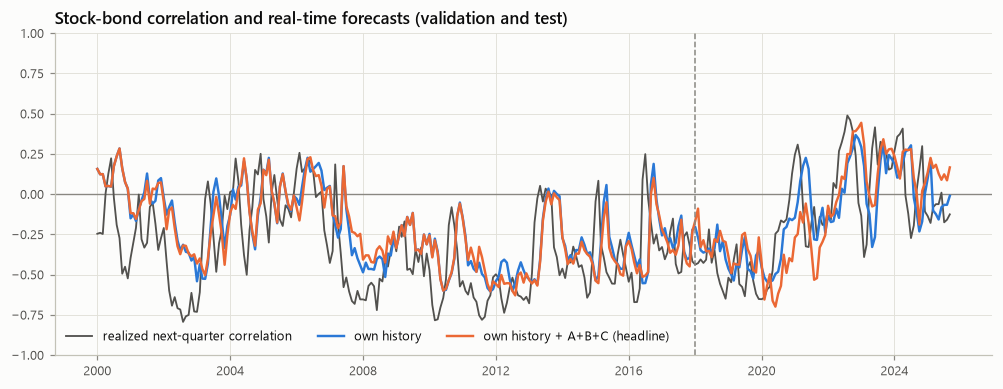

In [22]:
# Correlation history with forecasts (validation; test months are added only after the test run).
fig, ax = plt.subplots(figsize=(11, 3.8))
idx = F[("A", "Headline")].index
t = idx.to_timestamp()
ax.plot(df.loc[idx].index.to_timestamp(), df.loc[idx, "y"], color=INK2, linewidth=1.2, label="realized next-quarter correlation")
ax.plot(t, F[("bench", "Own history")].loc[idx], color=PALETTE[0], label="own history")
ax.plot(t, F[("A+B+C", "Headline")].loc[idx], color=PALETTE[1], label="own history + A+B+C (headline)")
if RUN_TEST:
    ax.axvline(pd.Period("2018-01", "M").to_timestamp(), color=MUTED, linestyle="--", linewidth=1)
zero_line(ax)
ax.set_ylim(-1, 1)
ax.set_title("Stock-bond correlation and real-time forecasts" + (" (validation and test)" if RUN_TEST else " (validation)"))
ax.legend(loc="lower left", ncol=3)
save_fig(fig, "fig_forecasts" + ("_test" if RUN_TEST else "_validation"))
plt.show()

## 11. Inside the headline combination (validation and test)

The accuracy-weighted combination of the headline models is the only model with a positive test $R^2$ vs. own history (+1.2%, Clark–West p = 0.19, so not significant). This section opens it up the way Section 8 opened up the single best models. It is descriptive only and runs after the test, so it cannot affect the design or Table 1.

* **Why it can be opened up exactly.** Each group's headline forecast is (ridge + PCR) / 2. Both are linear in the partialled-out, standardized predictors and share the same own-history base, so headline$_g$ = own history + $Z_g\beta_g$. The combination is $\sum_g w_{g,t}\,\text{headline}_g$ with weights summing to 1, so
  $$\text{combination}_t = \text{own history}_t + \sum_g w_{g,t}\, Z_{g,t}\,\beta_g .$$
  Predictor $x$ of group $g$ therefore has an **implied coefficient** $w_{g,t}\,\beta_g(x)$ in month $t$. It moves with both the yearly refits and the monthly weights.
* **How the coefficients are recovered.** Each refit's hyperparameters are recovered by re-running the same deterministic CV. The cell checks that the rebuilt ridge, PCR, headline and combination forecasts all match the scored ones exactly.
* Coefficients use the same standardized scale as Section 8. **Contributions** (weight × coefficient × predictor) sum exactly to the combination minus own history.


In [23]:
# ---- Inside the headline combination: implied coefficients, weights and contributions ----
# Each group's headline forecast is (ridge + PCR) / 2. Both are linear in the partialled-out, standardized predictors,
# and both share the same own-history base, so headline_g = own history + Z_g @ beta_g. The combination is
# sum_g w_g * headline_g, and the weights sum to 1, so
#     combination = own history + sum_g w_g * Z_g @ beta_g,
# i.e. predictor x of group g has implied coefficient w_g,t * beta_g(x) in month t. Nothing below is re-chosen: CV is
# simply re-run with the same deterministic code to recover each refit's hyperparameter, and every rebuilt forecast is
# checked against the one that was scored.
CB_YEARS = VAL_YEARS + (TEST_YEARS if RUN_TEST else [])
cb_idx = val_idx.append(test_idx) if RUN_TEST else val_idx            # scored months (2017-11/12 excluded)


def headline_coefs(grp):
    cols = set_cols(grp)
    std, contrib = {}, []
    for Y in CB_YEARS:
        end = VAL_END if Y in VAL_YEARS else TEST_END
        k_r, k_p = one_year(Ridge(), df, cols, Y, end)[1]["k"], one_year(PCR(len(cols)), df, cols, Y, end)[1]["k"]
        fit = fit_rows(df, Y)
        ev = df.loc[pd.Period(f"{Y}-01", "M"): min(pd.Period(f"{Y}-12", "M"), end)]
        Z, Z_e, r, base = partial_out(fit[cols].to_numpy(float), fit["h"].to_numpy(float), fit["y"].to_numpy(float),
                                      ev[cols].to_numpy(float), ev["h"].to_numpy(float))
        U, s, Vt = np.linalg.svd(Z, full_matrices=False)
        b_ridge = Vt.T @ (s / (s ** 2 + RIDGE_REL_GRID[k_r] * s[0] ** 2) * (U.T @ r))
        Fz = Z @ Vt.T
        b_pcr = Vt.T[:, :k_p] @ ((Fz.T @ r) / (Fz ** 2).sum(axis=0))[:k_p]
        beta = (b_ridge + b_pcr) / 2
        assert np.allclose(base + Z_e @ b_ridge, F[(grp, "Ridge")].loc[ev.index], atol=1e-8), (grp, "Ridge", Y)
        assert np.allclose(base + Z_e @ b_pcr, F[(grp, "PCR")].loc[ev.index], atol=1e-8), (grp, "PCR", Y)
        assert np.allclose(base + Z_e @ beta, F[(grp, "Headline")].loc[ev.index], atol=1e-8), (grp, "Headline", Y)
        std[Y] = pd.Series(beta, index=cols)
        contrib.append(pd.DataFrame(Z_e * beta, index=ev.index, columns=cols))
    return pd.DataFrame(std).T, pd.concat(contrib)


with timer("headline coefficients, A/B/C"):
    HL = {grp: headline_coefs(grp) for grp in "ABC"}

W_cb = COMBO["Headline"][1].loc[cb_idx]
own_cb = F[("bench", "Own history")].loc[cb_idx]
# monthly contribution of each predictor to (combination - own history): weight x headline contribution
CONTRIB_CB = pd.concat([HL[grp][1].loc[cb_idx].mul(W_cb[grp], axis=0) for grp in "ABC"], axis=1)
assert np.allclose(own_cb + CONTRIB_CB.sum(axis=1), F[("Combination", "Headline")].loc[cb_idx], atol=1e-8)
# implied monthly coefficient of each predictor in the combination
COEF_CB = pd.concat([pd.DataFrame(HL[grp][0].loc[cb_idx.year].to_numpy(), index=cb_idx, columns=HL[grp][0].columns)
                     .mul(W_cb[grp], axis=0) for grp in "ABC"], axis=1)

periods = {"validation": val_idx} | ({"test": test_idx} if RUN_TEST else {})
y_cb = df.loc[cb_idx, "y"]
grp_tab = {}
for grp in "ABC":
    row = {}
    for p, idx in periods.items():
        row[f"mean weight, {p} (%)"] = 100 * W_cb.loc[idx, grp].mean()
        row[f"R2 vs own, {p} (%)"] = oos_r2(y_cb.loc[idx], F[(grp, "Headline")].loc[idx], own_cb.loc[idx])
        row[f"mean |shift|, {p}"] = CONTRIB_CB.loc[idx, GROUPS[grp]].sum(axis=1).abs().mean()
    grp_tab[f"{grp} ({GROUP_NAMES[grp]})"] = row
grp_tab = pd.DataFrame(grp_tab).T
grp_tab.index.name = "group (headline)"
print("Combination (headline): weights, accuracy and size of each group's push away from own history.")
display(grp_tab.round(3))
save_table(grp_tab, "table_combo_groups", "{:.3f}")

var_tab = {}
for grp in "ABC":
    for c in GROUPS[grp]:
        row = {}
        for p, idx in periods.items():
            row[f"mean implied coef per sd, {p}"] = COEF_CB.loc[idx, c].mean()
            row[f"mean |contribution|, {p}"] = CONTRIB_CB.loc[idx, c].abs().mean()
        var_tab[(GROUP_NAMES[grp], c)] = row
var_tab = pd.DataFrame(var_tab).T
var_tab.index.names = ["group", "predictor"]
print("Implied coefficients of the combination (per 1 sd of the partialled-out predictor) and average absolute "
      "contribution to the forecast's departure from own history.")
display(var_tab.round(3))
save_table(var_tab, "table_combo_coefs", "{:.3f}")

# Diagnostic (chosen after seeing the test, so NOT a candidate model): how much of the combination's result is
# simple shrinkage? With weights near 1/3 and B contributing exactly nothing, the combination is roughly
# own history + (A shift + C shift) / 3.
d_shift = {grp: F[(grp, "Headline")] - F[("bench", "Own history")] for grp in "AC"}
diag = {}
for p, idx in periods.items():
    own_p = own_cb.loc[idx]
    r2p = lambda f: oos_r2(y_cb.loc[idx], f.loc[idx], own_p)
    diag[p] = {"combination, accuracy-weighted (pre-registered)": r2p(F[("Combination", "Headline")]),
               "fixed equal weights (1/3 each)": r2p(F[("bench", "Own history")] + (d_shift["A"] + d_shift["C"]) / 3),
               "own history + full C shift (= C headline)": r2p(F[("C", "Headline")]),
               "own history + 1/2 x C shift": r2p(F[("bench", "Own history")] + d_shift["C"] / 2),
               "own history + 1/3 x C shift": r2p(F[("bench", "Own history")] + d_shift["C"] / 3)}
diag = pd.DataFrame(diag)
diag.columns = [f"R2 vs own, {p} (%)" for p in diag.columns]
diag.index.name = "diagnostic (ex post, not a model)"
print("Diagnostic: the combination behaves like shrinkage of the group signals toward own history.")
display(diag.round(2))
save_table(diag, "table_combo_shrinkage_diagnostic", "{:.2f}")


[headline coefficients, A/B/C: 0.3s]
Combination (headline): weights, accuracy and size of each group's push away from own history.


,"mean weight, validation (%)","R2 vs own, validation (%)","mean |shift|, validation","mean weight, test (%)","R2 vs own, test (%)","mean |shift|, test"
group (headline),,,,,,
A (Macro),30.197,-14.601,0.015,32.191,-2.004,0.011
B (Liquidity),34.068,-0.011,0.000,33.740,0.000,0.000
C (News),35.734,7.625,0.021,34.069,-9.792,0.035


Implied coefficients of the combination (per 1 sd of the partialled-out predictor) and average absolute contribution to the forecast's departure from own history.


mean implied coef per sd, validation  mean |contribution|, validation  mean implied coef per sd, test  \
group     predictor                                                                                                                     
Macro     infl_yoy                                             0.003                            0.004                           0.004   
          infl_vol12                                          -0.005                            0.008                          -0.003   
          exp_infl_mich                                        0.003                            0.003                           0.002   
          unemp_chg12                                         -0.005                            0.007                          -0.000   
          tbill                                                0.002                            0.003                           0.008   
          term_spread                                          0.001                            0.002                          -0.000   
Liquidity credit_spread                                       -0.000                            0.000                          -0.000   
          cp_spread                                            0.000                            0.000                           0.000   
          vix_monthend                                        -0.000                            0.000                           0.000   
          treasury_noise                                       0.000                            0.000                           0.000   
          ps_liquidity                                        -0.000                            0.000                          -0.000   
News      epu_overall                                          0.008                            0.007                           0.009   
          epu_monetary                                         0.003                            0.003                           0.007   
          emv_inflation_share                                  0.012                            0.010                           0.016   
          emv_rates_share                                      0.016                            0.012                           0.023   
          emv_monetary_share                                  -0.010                            0.010                          -0.024   
          emv_macro_news_share                                -0.001                            0.005                          -0.008   

                                mean |contribution|, test  
group     predictor                                        
Macro     infl_yoy                                  0.004  
          infl_vol12                                0.002  
          exp_infl_mich                             0.003  
          unemp_chg12                               0.003  
          tbill                                     0.006  
          term_spread                               0.003  
Liquidity credit_spread                             0.000  
          cp_spread                                 0.000  
          vix_monthend                              0.000  
          treasury_noise                            0.000  
          ps_liquidity                              0.000  
News      epu_overall                               0.014  
          epu_monetary                              0.007  
          emv_inflation_share                       0.023  
          emv_rates_share                           0.028  
          emv_monetary_share                        0.021  
          emv_macro_news_share                      0.007

Diagnostic: the combination behaves like shrinkage of the group signals toward own history.


,"R2 vs own, validation (%)","R2 vs own, test (%)"
"diagnostic (ex post, not a model)",,
"combination, accuracy-weighted (pre-registered)",4.75,1.19
fixed equal weights (1/3 each),4.63,1.76
own history + full C shift (= C headline),7.62,-9.79
own history + 1/2 x C shift,5.76,1.93
own history + 1/3 x C shift,4.27,2.81


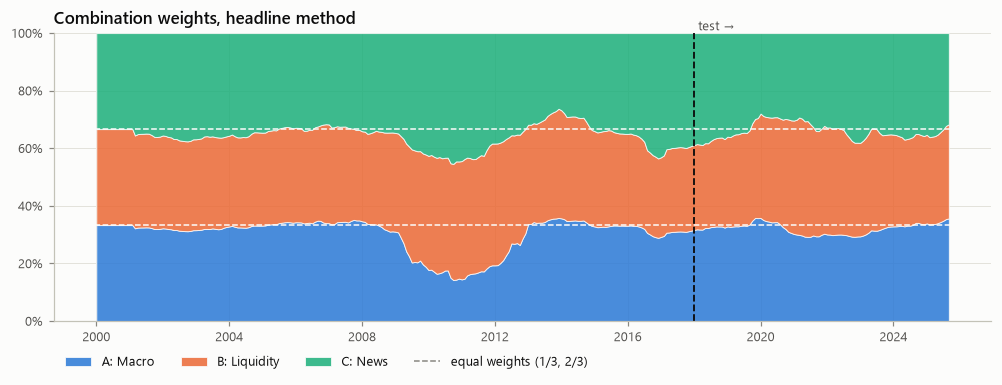

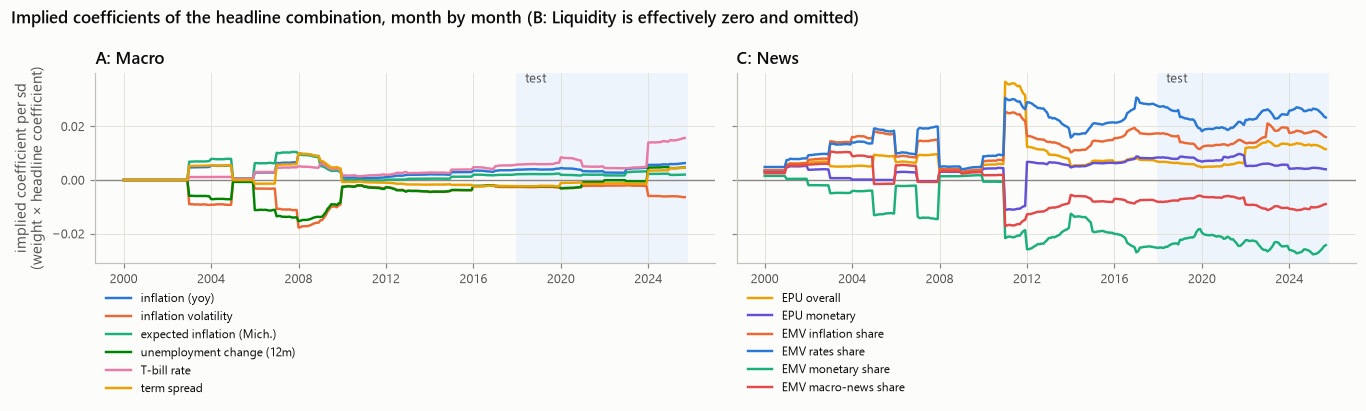

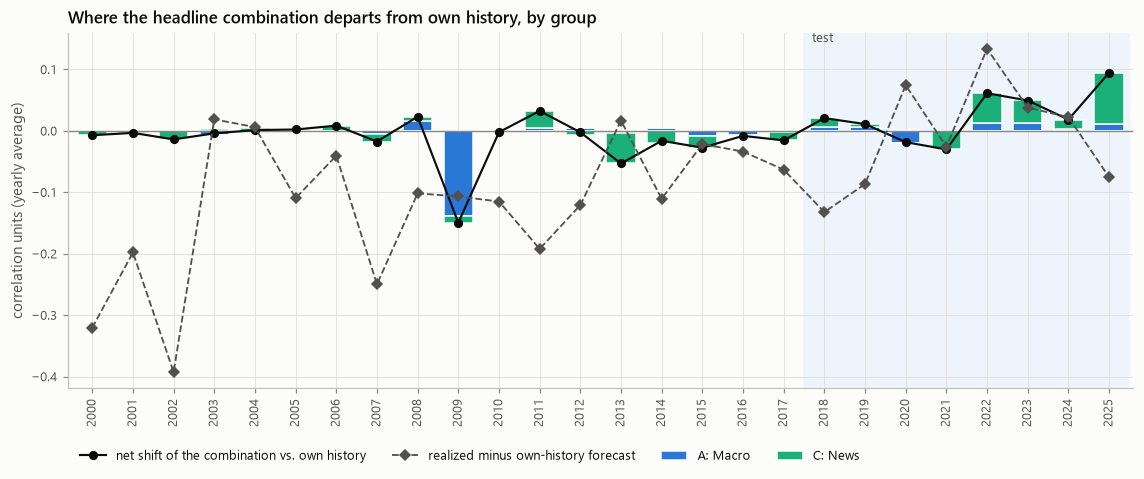

Test: corr(net shift, own-history miss) = 0.16; shift had the right sign in 45% of months.
  A: corr(its shift, miss) = 0.03; MSE change vs. own history if only this group's shift were applied: +0.0000
  B: corr(its shift, miss) = -0.03; MSE change vs. own history if only this group's shift were applied: +0.0000
  C: corr(its shift, miss) = 0.18; MSE change vs. own history if only this group's shift were applied: -0.0014


In [24]:
GROUP_COLOR = dict(zip("ABC", PALETTE[:3]))          # same colors as the validation weights chart
TEST_START = pd.Period("2018-01", "M")


def shade_test(ax, yearly=False):
    if RUN_TEST:
        lo = 2017.5 if yearly else TEST_START.to_timestamp()
        hi = CB_YEARS[-1] + 0.5 if yearly else cb_idx[-1].to_timestamp(how="end")
        ax.axvspan(lo, hi, color="#eef4fc", zorder=0)
        ax.text(lo, 1.0, "  test", transform=ax.get_xaxis_transform(), va="top", color=INK2, fontsize=8.5)


# 1. weights through validation and test
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.stackplot(W_cb.index.to_timestamp(), W_cb.T.to_numpy(), labels=[f"{g}: {GROUP_NAMES[g]}" for g in W_cb.columns],
             colors=[GROUP_COLOR[g] for g in W_cb.columns], alpha=0.85, edgecolor=SURFACE, linewidth=0.6)
ax.axhline(1 / 3, color=SURFACE, linestyle="--", linewidth=1)
ax.axhline(2 / 3, color=SURFACE, linestyle="--", linewidth=1)
if RUN_TEST:
    ax.axvline(TEST_START.to_timestamp(), color=INK, linestyle="--", linewidth=1.2)
    ax.text(TEST_START.to_timestamp(), 1.0, " test →", transform=ax.get_xaxis_transform(), va="bottom",
            color=INK2, fontsize=8.5)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_title("Combination weights, headline method")
h, l = ax.get_legend_handles_labels()
h.append(plt.Line2D([], [], color=MUTED, linestyle="--", linewidth=1)); l.append("equal weights (1/3, 2/3)")
ax.legend(h, l, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=4)
save_fig(fig, "fig_combination_weights_full")
plt.show()

# 2. implied coefficients, one panel per group
# B is omitted: CV shrinks liquidity fully at every refit, so its implied coefficients are effectively zero (ridge at its largest penalty, PCR k = 0).
assert COEF_CB[GROUPS["B"]].abs().max().max() < 1e-3
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
for ax, grp in zip(axes, "AC"):
    shade_test(ax)
    spare = iter(c for c in PALETTE if c not in [VAR_COLOR[v] for v in GROUPS[grp] if v in VAR_COLOR])
    for c in GROUPS[grp]:
        col = VAR_COLOR[c] if c in VAR_COLOR else next(spare)       # Section 8 colors where a variable has one
        ax.plot(COEF_CB.index.to_timestamp(), COEF_CB[c], color=col, linewidth=1.6, label=VAR_LABEL.get(c, c.replace("_", " ")))
    zero_line(ax)
    ax.set_title(f"{grp}: {GROUP_NAMES[grp]}")
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=1, fontsize=8)
axes[0].set_ylabel("implied coefficient per sd\n(weight × headline coefficient)")
fig.suptitle("Implied coefficients of the headline combination, month by month (B: Liquidity is effectively zero and omitted)", x=0.01, ha="left",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "fig_combo_coefs_over_time")
plt.show()

# 3. yearly contributions by group vs. what own history missed
yr = cb_idx.year
G_contrib = pd.DataFrame({grp: CONTRIB_CB[GROUPS[grp]].sum(axis=1) for grp in "ABC"}).groupby(yr).mean()
gap_cb = (y_cb - own_cb).groupby(yr).mean()
fig, ax = plt.subplots(figsize=(12.5, 4.2))
shade_test(ax, yearly=True)
pos, neg = np.zeros(len(G_contrib)), np.zeros(len(G_contrib))
for grp in "AC":                                   # B's contribution is effectively zero
    v = G_contrib[grp].to_numpy()
    up, dn = np.where(v > 0, v, 0), np.where(v < 0, v, 0)
    ax.bar(G_contrib.index, up, bottom=pos, width=0.72, color=GROUP_COLOR[grp], edgecolor=SURFACE, linewidth=1,
           label=f"{grp}: {GROUP_NAMES[grp]}")
    ax.bar(G_contrib.index, dn, bottom=neg, width=0.72, color=GROUP_COLOR[grp], edgecolor=SURFACE, linewidth=1)
    pos += up
    neg += dn
ax.plot(G_contrib.index, G_contrib.sum(axis=1), color=INK, marker="o", markersize=5, linewidth=1.4,
        label="net shift of the combination vs. own history")
ax.plot(gap_cb.index, gap_cb, color=INK2, marker="D", markersize=5, linewidth=1.2, linestyle="--",
        label="realized minus own-history forecast")
zero_line(ax)
ax.set_xlim(CB_YEARS[0] - 0.6, CB_YEARS[-1] + 0.6)
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.tick_params(axis="x", labelrotation=90)
ax.set_ylabel("correlation units (yearly average)")
ax.set_title("Where the headline combination departs from own history, by group")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=5)
save_fig(fig, "fig_combo_contributions")
plt.show()

if RUN_TEST:
    net_t = CONTRIB_CB.loc[test_idx].sum(axis=1)
    gap_t = (y_cb - own_cb).loc[test_idx]
    print(f"Test: corr(net shift, own-history miss) = {net_t.corr(gap_t):.2f}; "
          f"shift had the right sign in {100 * (np.sign(net_t) == np.sign(gap_t)).mean():.0f}% of months.")
    for grp in "ABC":
        s = CONTRIB_CB.loc[test_idx, GROUPS[grp]].sum(axis=1)
        print(f"  {grp}: corr(its shift, miss) = {s.corr(gap_t):.2f}; MSE change vs. own history if only this "
              f"group's shift were applied: {((gap_t - s) ** 2).mean() - (gap_t ** 2).mean():+.4f}")


### Reading the combination

**1. The weights barely move.**
* Averaged over each window, the weights are close to one-third each: about 30 / 34 / 36% (A / B / C) in validation and 32 / 34 / 34% in the test.
* The one large swing came after the financial crisis: macro's weight fell to about 15% in 2010–11 after big crisis-period errors.
* With 3-month overlapping targets, 36 months is only about 12 independent quarters of errors, so the groups' recent MSEs rarely differ by much. The weight on news did **not** fall noticeably in the test, even though news on its own did badly there.

**2. So the combination works mainly as shrinkage toward own history.**
* Liquidity's headline forecast *is* own history: its implied coefficients are effectively zero. Yet it carries about a third of the weight.
* The combination is therefore roughly own history + ⅓ × (macro shift) + ⅓ × (news shift). It keeps the direction of the group signals but only about a third of their size.
* The diagnostic table makes this concrete. It is computed after the test, so it describes the outcome and is not a model we could have chosen:
  * **Fixed equal weights** would have done about as well as the accuracy weighting: +1.8% vs. +1.2% in the test, and +4.6% vs. +4.8% in validation. The accuracy weighting itself adds essentially nothing.
  * **News at full size** loses 9.8% to own history in the test. **News at one-third size** *gains* 2.8%.
* So the news signal still pointed the right way, on average, in 2018–2025. The full-size model overreacted to it, and the combination's built-in dilution is what made it hold up.

**3. What drives the implied coefficients.**
* They are the Section 8 news story at roughly a third of the size: the EMV rates and inflation shares positive (about +0.02 per sd in the test), the EMV monetary-policy share negative (about −0.02), overall EPU slightly positive.
* The macro coefficients are small throughout. The largest in the test is the T-bill rate, which turns more positive after 2024.

**4. When it helped and when it hurt (contributions chart).**
* **2022–2023, helped:** as inflation and rate hikes turned the stock-bond correlation positive, news pushed the forecast up (about +0.05 a year). This is the channel the rates/inflation-news variables are meant to capture: rate and inflation news made stocks and bonds fall together.
* **Validation, helped:** in 2009, macro (rising unemployment) pulled the forecast down by about 0.14, in the right direction.
* **2018–2019 and 2025, hurt:** news pushed the forecast up while the correlation came in below own history.
* Overall, in the test the net shift is only weakly aligned with what own history missed: correlation 0.16, right sign in 45% of months. Because the shifts are small, the misses cost little, and the 2022–23 gains outweigh them.

**Takeaway for the paper.**
* The combination's test edge comes from **shrinking a weak but real news signal**, not from the accuracy weights adapting.
* That is consistent with the forecast-combination literature (equal weights are hard to beat) and with the main result: news carries some information about which shocks dominate, but not enough to forecast at full strength out of sample.
* The +1.2% test gain is not statistically significant. The shrinkage numbers are ex post and should be presented as interpretation, not as a better model.


## Notes for the paper

* **Design changes relative to the team instructions doc:** hyperparameters are re-tuned by purged blocked CV at every yearly refit, and the windows are labeled burn-in / validation / test. The last two validation rows are not scored (overlap with test targets).
* **Caveats:** the burn-in lies entirely in the positive-correlation regime, so early validation years are hard for every model; 1987–99 data still makes up about 34–42% of each test-period fit. Validation $R^2$ for the *selected* methods is optimistic because selection happened there; only test results and the headline results are clean. The test window has about 31 independent quarters, so tests have low power, and a null result is informative.